# 07MIAR · Proyecto de programación
## Autores: Francis Arthur Poldark Palomino Marino, Jerson Danilo Paniagua Diaz y Celestino Moreno Romea
## Grupo: 22

## Clasificación de imágenes: una CNN desde cero y dos redes preentrenadas

Partimos de la comparación propuesta en la actividad: entrenar una red convolucional propia
y contrastarla con dos modelos preentrenados. Elegimos Oxford-IIIT Pet porque distinguir
37 razas permite estudiar hasta dónde llega cada estrategia con un conjunto de entrenamiento pequeño.

La construcción de la CNN desde cero fue la parte que más nos interesó explorar. Al probar
distintas configuraciones vimos que aumentar la red, añadir regularización o entrenar más
no garantizaba una mejora. Esa búsqueda amplió el trabajo y dio lugar a dos rondas de experimentos.
En la segunda retomamos preguntas que habían quedado abiertas tras la primera.

Este notebook reúne el proceso en una sola ejecución. Las tablas, curvas y comentarios
numéricos se calculan con los resultados de esa ejecución; no carga resultados de sesiones anteriores.
El índice permite seguir las decisiones y volver al código o a las gráficas que las sustentan.
Nuestro interés por mejorar la CNN no determina qué modelo elegimos: la selección se basa en validación.


<a id="indice"></a>

## Índice

<div class="toc">

[Cómo ejecutar este notebook](#uso)

[1. Planteamiento y criterio de comparación](#s1)

[2. Entorno de trabajo](#s2)

[3. Datos, inspección y preprocesamiento](#s3)

[4. Modelos y funciones de entrenamiento](#s4)

[5. Regularización de la CNN inicial](#s5)

[6. Búsqueda de configuraciones desde cero](#s6)

[7. Transfer learning y ajuste fino](#s7)

[8. Balance de la primera ronda y semillas](#s8)

[9. Segunda ronda: presupuesto, política y capacidad](#s9)

[10. Repeticiones y elección antes de test](#s10)

[11. Evaluación en test y análisis de errores](#s11)

[12. Comparación final y conclusiones](#s12)

[Limitaciones](#limites)

[Referencias](#referencias)

</div>

Para seguir el razonamiento, los apartados 5–10 alternan pruebas y análisis. La comparación global está en el apartado 12.


<a id="uso"></a>

## Cómo ejecutar este notebook

Abre el archivo en el mismo entorno de Jupyter que utilizaste para los entrenamientos.
Guárdalo y selecciona **Reiniciar kernel y ejecutar todas las celdas**. En Colab, activa
una GPU antes de ejecutar. La celda de entorno comprobará que TensorFlow puede utilizarla.
Se necesitan TensorFlow/Keras, NumPy, pandas, scikit-learn, Matplotlib, Pillow e IPython.

La primera ejecución descarga las imágenes, las anotaciones oficiales y los pesos de ImageNet.
No hay que aportar ZIP, modelos ni carpetas de resultados de las rondas anteriores.
Durante el trabajo se usan archivos temporales para recuperar la mejor época de cada red
y evitar decodificar repetidamente las imágenes. Los crea el programa y no forman parte de la entrega.
Si falta espacio, puede desactivarse `CACHE_IMAGES`; el entrenamiento será más lento.

Cada bloque muestra una barra que se actualiza en el mismo lugar, su tiempo de ejecución
y, al terminar, las métricas y curvas. El entrenamiento completo puede durar varias horas.
Mantén el equipo encendido, evita la suspensión y activa el guardado automático del notebook.
**No reinicies el kernel entre bloques:** los resultados se mantienen en la sesión y los pesos
son temporales. Si se interrumpe una celda con el kernel vivo, puede repetirse: los ensayos
ya completados se reutilizan y el ensayo interrumpido empieza de nuevo.

Al terminar, guarda el `.ipynb` con sus salidas. Ese archivo contiene el código, las tablas,
las figuras y la evidencia de ejecución que se utilizarán para generar el PDF con índice.


<a id="s1"></a>

## 1. Planteamiento y criterio de comparación

Usamos la partición oficial de test y dividimos únicamente `trainval` en entrenamiento
y validación, de forma estratificada y con semilla 42. Fijamos F1 macro como criterio para
elegir la época y la configuración. En caso de empate usamos menor entropía cruzada y,
después, el identificador de la configuración. Accuracy y top-3 complementan la comparación.

Primero aislamos el efecto de Batch Normalization, aumentos, L2 y dropout en una CNN base.
Después hacemos una búsqueda progresiva de arquitecturas y comparamos MobileNetV2 y
EfficientNetB0, tanto con extractor congelado como con ajuste fino. La primera ronda
da lugar a nuevas pruebas sobre el presupuesto de entrenamiento y la generalización.

Las semillas 123 y 2026 sirven para observar la variación, sin elegir la semilla más favorable.
Los tres finalistas de test mantienen la semilla 42. La elección se muestra en una tabla
antes de ejecutar test y no se cambia después de consultar sus resultados.

En las primeras versiones del trabajo ya habíamos consultado este test. Esta ejecución
es una reevaluación del mismo conjunto, no una estimación completamente ciega.
No añadimos ensayos para corregir errores concretos de test.


<a id="s2"></a>

## 2. Entorno de trabajo

Usamos lotes de 32, semillas explícitas y operaciones deterministas. Con GPU activamos
precisión mixta, manteniendo la salida softmax y las métricas en float32. Las versiones
y el dispositivo se muestran al ejecutar, porque pueden influir en los resultados y tiempos.


In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '1')

import gc, hashlib, json, platform, shutil, sys, time
from pathlib import Path
from datetime import datetime, timedelta
from tempfile import TemporaryDirectory
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, log_loss, precision_score,
                             recall_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from IPython.display import display, Markdown, HTML
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

def show_table(frame):
    display(HTML(frame.to_html(index=False, border=0)))

SEED = 42
BATCH_SIZE = 32
CACHE_IMAGES = True
ALLOW_CPU = False

gpus = tf.config.list_physical_devices('GPU')
if not gpus and not ALLOW_CPU:
    raise RuntimeError('TensorFlow no detecta GPU. Selecciona el kernel con CUDA o activa GPU en Colab.')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
keras.mixed_precision.set_global_policy('mixed_float16' if gpus else 'float32')
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

# Espacio temporal de esta ejecución; no lee ni modifica las carpetas antiguas.
temporary_workspace = TemporaryDirectory(prefix='07MIAR_')
TEMP_DIR = Path(temporary_workspace.name)
TRIALS = {}
EVALUATION_LOCKED = False
execution_start = time.perf_counter()
gpu_names = [tf.config.experimental.get_device_details(g).get('device_name', g.name) for g in gpus]
show_table(pd.DataFrame({
    'Dato': ['Python', 'TensorFlow', 'Keras', 'Sistema', 'Dispositivo', 'Precisión', 'Semilla', 'Batch'],
    'Valor': [platform.python_version(), tf.__version__, keras.__version__, platform.system(),
              ', '.join(gpu_names) or 'CPU', keras.mixed_precision.global_policy().name, SEED, BATCH_SIZE]
}))

# Una convolución y su gradiente comprueban que el dispositivo funciona.
with tf.device('/GPU:0' if gpus else '/CPU:0'):
    probe = keras.Sequential([keras.Input((32, 32, 3)), layers.Conv2D(4, 3),
                              layers.GlobalAveragePooling2D(), layers.Dense(2, dtype='float32')])
    probe.compile(optimizer='adam', loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    probe_loss = float(probe.train_on_batch(tf.random.uniform((2, 32, 32, 3)), np.array([0, 1])))
assert np.isfinite(probe_loss)
del probe
keras.backend.clear_session()
display(Markdown('Comprobación de convolución y gradiente: **correcta**.'))


I0000 00:00:1795189607.452935  156011 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795189614.281884  156011 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1795189618.035241  156011 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


Dato,Valor
Python,3.12.3
TensorFlow,2.21.0
Keras,3.15.1
Sistema,Linux
Dispositivo,NVIDIA GeForce RTX 5090 Laptop GPU
Precisión,mixed_float16
Semilla,42
Batch,32


W0000 00:00:1795189618.058906  156011 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


Comprobación de convolución y gradiente: **correcta**.

In [2]:
def duration_text(seconds):
    return str(timedelta(seconds=round(seconds)))


class ExperimentProgress:
    """Actualiza una sola salida por bloque; el estado final queda en el notebook."""
    def __init__(self, title, total):
        self.title, self.total = title, int(total)
        self.completed = self.reused = 0
        self.started = datetime.now().astimezone()
        self.clock = time.perf_counter()
        self.view = None

    def update(self, detail="", fraction=0.0, status="En ejecución"):
        percent = 100 * min(1, (self.completed + fraction) / max(1, self.total))
        text = (f"<b>{escape(self.title)}</b> · {status} · {self.completed}/{self.total} ensayos"
                f'<div style="background:#eee;height:8px;margin:6px 0">'
                f'<div style="background:#517c67;height:8px;width:{percent:.1f}%"></div></div>'
                f"{escape(detail)}<br>"
                f"Inicio: {self.started:%d/%m/%Y %H:%M:%S %Z} · "
                f"Tiempo: {duration_text(time.perf_counter() - self.clock)}")
        if self.view is None:
            self.view = display(HTML(text), display_id=True)
        else:
            self.view.update(HTML(text))

    def finish_trial(self, result, reused=False):
        self.completed += 1
        self.reused += int(reused)
        self.update(f"{result['label']}: {result['epochs_run']} épocas; "
                    f"mejor F1 de validación {result['f1_macro']:.4f}.")

    def __enter__(self):
        self.update()
        return self

    def __exit__(self, exc_type, exc, traceback):
        finished = exc_type is None and self.completed == self.total
        status = "Completado" if finished else "Interrumpido"
        detail = f"Fin: {datetime.now().astimezone():%d/%m/%Y %H:%M:%S %Z}."
        if self.reused:
            detail += f" Reutilizados en este kernel: {self.reused}."
        if exc_type is not None:
            detail += " La celda muestra el error; este bloque no se da por completado."
        self.update(detail, status=status)
        return False


class TrainingProgress(keras.callbacks.Callback):
    def __init__(self, progress, label, epochs):
        super().__init__()
        self.progress, self.label, self.epochs = progress, label, epochs

    def on_epoch_begin(self, epoch, logs=None):
        self.used_lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))
        self.progress.update(f"{self.label} · época {epoch + 1}/{self.epochs}",
                             fraction=epoch / self.epochs)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        logs['learning_rate'] = self.used_lr
        self.progress.update(
            f"{self.label} · época {epoch + 1}/{self.epochs} · "
            f"accuracy {logs.get('accuracy', float('nan')):.3f} · "
            f"F1 validación {logs.get('val_f1_macro', float('nan')):.3f}",
            fraction=(epoch + 1) / self.epochs)


def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def trial_name(config):
    stage = config['stage']
    candidate = ' · ' + config['candidate'] if config.get('candidate') else ''
    tuning = (f" · {config['unfreeze_layers']} capas · LR {config['learning_rate']:g}"
              if 'unfreeze_layers' in config else '')
    return f"{config['family']} · {stage}{candidate}{tuning} · s{config['seed']}"


def ranked_trials(results):
    # El desempate también se fija antes de consultar los resultados.
    return sorted(results, key=lambda r: (-r['f1_macro'], r['cross_entropy'], r['trial_id']))


<a id="s3"></a>

## 3. Datos, inspección y preprocesamiento

Oxford-IIIT Pet contiene 37 clases de gatos y perros, con diferencias visuales a veces sutiles.
Su tamaño permite entrenar una CNN propia y estudiar la ventaja de las características
aprendidas en ImageNet. Usamos todas las imágenes anotadas en las particiones oficiales.

La inspección muestra clases, dimensiones y ejemplos, y comprueba que no haya identificadores
compartidos entre particiones. Las etiquetas se ordenan de la misma forma en las tres.
Las imágenes se convierten a RGB y se redimensionan conservando la proporción mediante
relleno: 128×128 para la CNN y 224×224 para las preentrenadas. Los aumentos solo actúan
durante el entrenamiento y no afectan a validación ni a test.


In [3]:
def locate_extracted(returned, child):
    p = Path(returned)
    candidates = [p/child, p.parent/child, p.parent/(p.name.replace('.tar.gz','')+'_extracted')/child]
    for q in candidates:
        if q.is_dir(): return q
    raise FileNotFoundError(f'No encontramos {child} tras extraer {p}. Revisar salida de get_file.')

images_dir=locate_extracted(keras.utils.get_file(
    fname='oxford-iiit-pet-images.tar.gz',origin='https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz',
    extract=True,cache_subdir='datasets/oxford_iiit_pet'), 'images')
annotations_dir=locate_extracted(keras.utils.get_file(
    fname='oxford-iiit-pet-annotations.tar.gz',origin='https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz',
    extract=True,cache_subdir='datasets/oxford_iiit_pet'), 'annotations')

def read_split(filename):
    rows=[]
    for line in (annotations_dir/filename).read_text().splitlines():
        if not line.strip() or line.startswith('#'): continue
        image_id,c,s,b=line.split()
        rows.append({'image_id':image_id,'path':str(images_dir/(image_id+'.jpg')),
                     'class_name':image_id.rsplit('_',1)[0].replace('_',' ').title(),
                     'official_label':int(c),'species':'gato' if s=='1' else 'perro'})
    return pd.DataFrame(rows)

trainval=read_split('trainval.txt'); test_df=read_split('test.txt')
class_names=sorted(trainval.class_name.unique())
mapping={name:i for i,name in enumerate(class_names)}
assert len(mapping)==37 and set(test_df.class_name)==set(mapping)
for frame in (trainval,test_df): frame['label']=frame.class_name.map(mapping).astype('int32')
train_df,valid_df=train_test_split(trainval,test_size=.2,stratify=trainval.label,random_state=SEED)
train_df=train_df.reset_index(drop=True); valid_df=valid_df.reset_index(drop=True)
for a,b in [(train_df,valid_df),(train_df,test_df),(valid_df,test_df)]:
    assert set(a.image_id).isdisjoint(b.image_id)
assert (len(train_df),len(valid_df),len(test_df))==(2944,736,3669)
for split,frame in [('train',train_df),('valid',valid_df),('test',test_df)]:
    assert frame.path.map(lambda p: Path(p).is_file()).all()
display(Markdown(f'**{len(trainval)+len(test_df):,} imágenes anotadas**, '
    f'**{len(class_names)} clases**; train/validación/test: '
    f'**{len(train_df)}/{len(valid_df)}/{len(test_df)}**.'))
display(pd.DataFrame({'train':train_df.class_name.value_counts(),
                      'valid':valid_df.class_name.value_counts(),
                      'test':test_df.class_name.value_counts()}).sort_index())


**7,349 imágenes anotadas**, **37 clases**; train/validación/test: **2944/736/3669**.

,train,valid,test
class_name,,,
Abyssinian,80,20,98
American Bulldog,80,20,100
American Pit Bull Terrier,80,20,100
Basset Hound,80,20,100
Beagle,80,20,100
Bengal,80,20,100
Birman,80,20,100
Bombay,77,19,88
Boxer,80,20,99


,anchura,altura
count,3680.0,3680.0
mean,431.0,383.4
std,126.3,116.8
min,114.0,108.0
25%,333.0,333.0
50%,500.0,375.0
75%,500.0,500.0
max,3264.0,2606.0


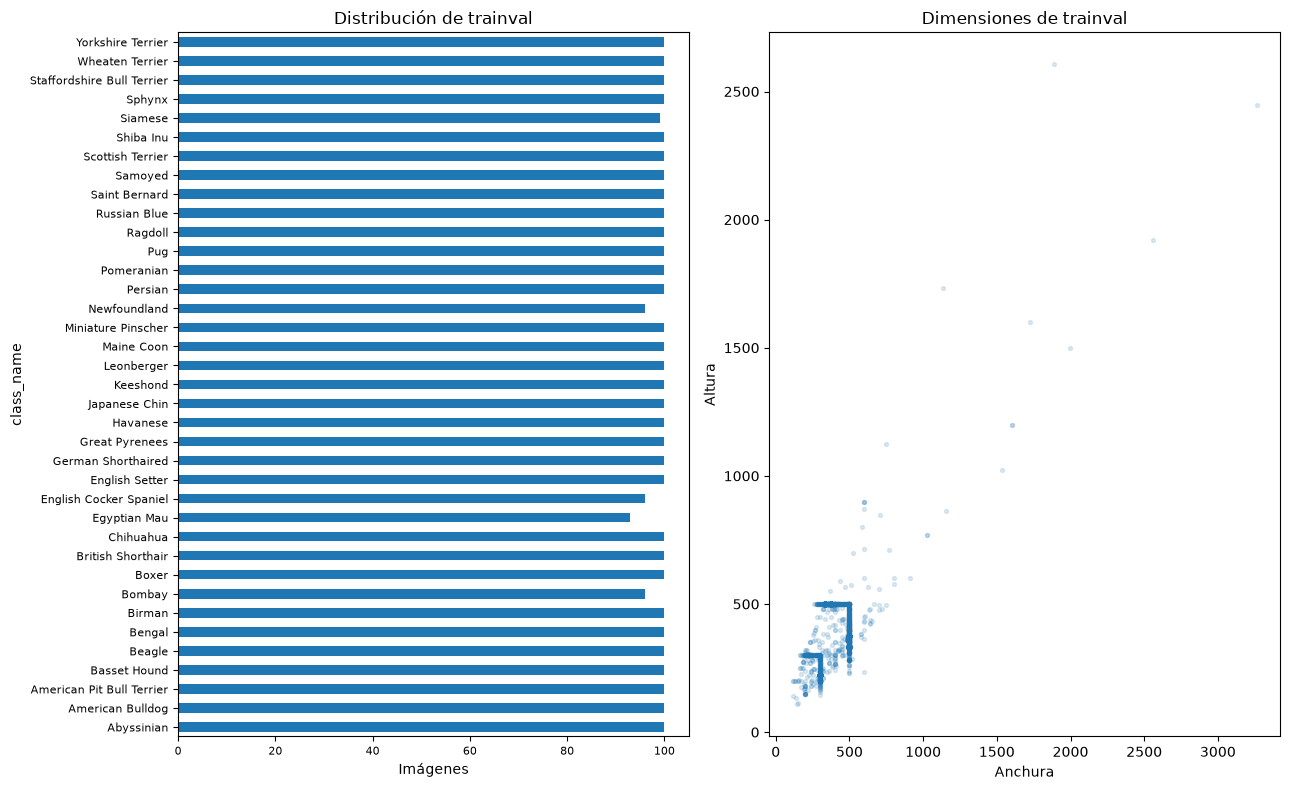

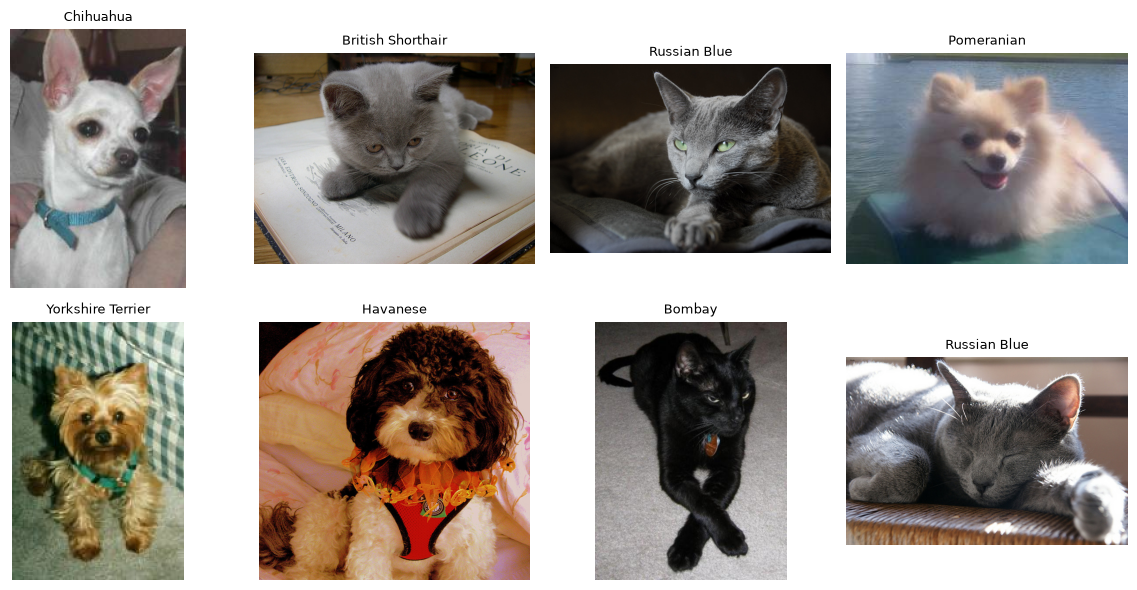

La referencia de accuracy para una predicción uniforme entre clases es **2.70%**.

In [4]:
dimensions=[]; failures=[]
for p in trainval.path:
    try:
        with Image.open(p) as im:
            dimensions.append(im.size); im.verify()
    except (OSError,ValueError) as e:
        failures.append((p,str(e)))
if failures: raise RuntimeError(f'Hay {len(failures)} imágenes no verificables. Revisar antes de excluir datos.')
shape_df=pd.DataFrame(dimensions,columns=['anchura','altura'])
display(shape_df.describe().round(1))
fig,axs=plt.subplots(1,2,figsize=(13,8))
trainval.class_name.value_counts().sort_index().plot.barh(ax=axs[0],fontsize=8)
axs[0].set(title='Distribución de trainval',xlabel='Imágenes')
axs[1].scatter(shape_df.anchura,shape_df.altura,alpha=.15,s=8)
axs[1].set(title='Dimensiones de trainval',xlabel='Anchura',ylabel='Altura')
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(2,4,figsize=(12,6))
for ax,(_,row) in zip(axs.flat,train_df.sample(8,random_state=SEED).iterrows()):
    with Image.open(row.path) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(row.class_name,fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()
display(Markdown(f'La referencia de accuracy para una predicción uniforme entre clases es **{1/len(class_names):.2%}**.'))


<a id="s4"></a>

## 4. Modelos y funciones de entrenamiento

La CNN base tiene tres bloques de 32/64/128 filtros. Cada bloque aplica dos convoluciones
3×3, Batch Normalization, ReLU y max-pooling. Global average pooling reduce el tamaño de
la cabeza, que termina con 128 unidades densas y una salida softmax de 37 clases.

MobileNetV2 y EfficientNetB0 conservan sus extractores de ImageNet y sustituyen la cabeza
por global average pooling, dropout de 0,20 y softmax. Primero se entrena la cabeza con
el extractor congelado. Después se descongelan selectivamente sus últimas capas y se
recompila con una tasa de aprendizaje menor. Batch Normalization del extractor permanece
congelada y en modo inferencia.

La CNN normaliza a [0,1], MobileNetV2 a [-1,1] y EfficientNetB0 recibe [0,255], ya que
incorpora su propia normalización. Contamos el F1 a partir de la matriz de confusión
acumulada de toda la época, no como media de los F1 de cada lote.

Cada ensayo conserva la época de mayor F1 de validación. En la política inicial se detiene
tras seis épocas sin mejora y se reduce la tasa si la pérdida de validación se estanca tres.
Las curvas de pérdida incluyen L2; la entropía cruzada calculada a partir de las predicciones
no incluye esa penalización. La accuracy de entrenamiento utilizada para medir la brecha
se recalcula sin aumentos ni dropout, sobre la mejor época.


In [5]:
# Métrica macro F1 acumulada por época
@keras.utils.register_keras_serializable(package="OxfordPets")
class MacroF1(keras.metrics.Metric):
    """F1 macro de toda la época; NO media de F1 calculados por lote."""
    def __init__(self, num_classes, name="f1_macro", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = int(num_classes)
        self.cm = self.add_weight(name="confusion", shape=(self.num_classes, self.num_classes),
                                  initializer="zeros", dtype="float32")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        weights = None
        if sample_weight is not None:
            weights = tf.broadcast_to(tf.reshape(tf.cast(sample_weight, tf.float32), [-1]), tf.shape(y_true))
        cm = tf.math.confusion_matrix(y_true, y_pred, num_classes=self.num_classes,
                                      weights=weights, dtype=tf.float32)
        self.cm.assign_add(cm)

    def result(self):
        tp = tf.linalg.diag_part(self.cm)
        denominator = tf.reduce_sum(self.cm, axis=0) + tf.reduce_sum(self.cm, axis=1)
        return tf.reduce_mean(tf.math.divide_no_nan(2.0 * tp, denominator))

    def reset_state(self):
        self.cm.assign(tf.zeros_like(self.cm))

    def get_config(self):
        return {**super().get_config(), "num_classes": self.num_classes}


In [6]:
def make_dataset(frame, size=128, training=False, seed=42, batch_size=None, cache=True):
    batch_size = int(batch_size or BATCH_SIZE)
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.path.astype(str).to_numpy(), frame.label.to_numpy(dtype='int32')))

    @tf.autograph.experimental.do_not_convert
    def decode(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3, try_recover_truncated=True)
        image = tf.image.resize_with_pad(image, size, size, antialias=True)
        return tf.cast(image, tf.float32), label

    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    if cache and CACHE_IMAGES:
        # Solo datos deterministas. El barajado y los aumentos van después.
        key = stable_hash({'size': size, 'rows': frame[['image_id', 'label']].values.tolist()})[:20]
        prefix = TEMP_DIR / ('images_' + key)
        estimate = len(frame) * size * size * 3 * 4
        if not Path(str(prefix) + '.index').exists():
            if shutil.disk_usage(TEMP_DIR).free < estimate + 2**30:
                raise OSError('Falta espacio para la caché temporal. Desactiva CACHE_IMAGES y reinicia.')
        ds = ds.cache(str(prefix))
    if training:
        ds = ds.shuffle(min(len(frame), 1024), seed=int(seed), reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


In [7]:
# Arquitecturas desde cero y preentrenadas
def augmentation_layer(seed):
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed, dtype="float32"),
        layers.RandomRotation(0.04, seed=seed + 1, dtype="float32"),
        layers.RandomZoom(0.08, seed=seed + 2, dtype="float32"),
        layers.RandomContrast(0.08, seed=seed + 3, dtype="float32"),
    ], name="augmentation")


def build_model(config):
    cfg = config
    size, seed = int(cfg["size"]), int(cfg["seed"])
    inputs = keras.Input(shape=(size, size, 3), dtype="float32", name="rgb_0_255")
    x = augmentation_layer(seed)(inputs) if cfg.get("augmentation") else inputs
    reg = regularizers.l2(float(cfg.get("l2", 0))) if cfg.get("l2", 0) else None
    if cfg["family"] == "scratch":
        x = layers.Rescaling(1 / 255.0, dtype="float32")(x)
        for block, filters in enumerate(cfg["filters"]):
            for conv in range(int(cfg.get("convs_per_block", 2))):
                x = layers.Conv2D(int(filters), int(cfg.get("kernel_size", 3)), padding="same",
                                  use_bias=not cfg.get("batch_norm", True), kernel_regularizer=reg)(x)
                if cfg.get("batch_norm", True):
                    x = layers.BatchNormalization()(x)
                x = layers.Activation("relu")(x)
            x = layers.MaxPooling2D()(x)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(int(cfg.get("dense_units", 128)), activation="relu", kernel_regularizer=reg)(x)
    else:
        if cfg["family"] == "mobilenet":
            x = layers.Rescaling(1 / 127.5, offset=-1, dtype="float32", name="mobilenet_preprocess")(x)
            backbone = keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                                      input_shape=(size, size, 3))
        elif cfg["family"] == "efficientnet":
            # EfficientNet ya incluye Rescaling; recibe RGB [0,255]. No dividir otra vez.
            x = layers.Activation("linear", dtype="float32", name="efficientnet_input_float32")(x)
            backbone = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                         input_shape=(size, size, 3))
        else:
            raise ValueError(f"Familia desconocida: {cfg['family']}")
        backbone.trainable = False
        x = backbone(x, training=False)  # BN en inferencia también durante el ajuste fino.
        x = layers.GlobalAveragePooling2D()(x)
    if cfg.get("dropout", 0):
        x = layers.Dropout(float(cfg["dropout"]), seed=seed + 4)(x)
    outputs = layers.Dense(len(class_names), activation="softmax", dtype="float32", name="probabilities")(x)
    return keras.Model(inputs, outputs, name=f"pets_{cfg['family']}")


def configure_fine_tuning(model, last_layers):
    backbones = [x for x in model.layers if isinstance(x, keras.Model) and not isinstance(x, keras.Sequential)]
    if len(backbones) != 1:
        raise ValueError("No se pudo identificar inequívocamente el backbone.")
    backbone = backbones[0]
    backbone.trainable = True
    cut = max(0, len(backbone.layers) - int(last_layers))
    for index, layer in enumerate(backbone.layers):
        layer.trainable = index >= cut and not isinstance(layer, layers.BatchNormalization)
    return model


def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(float(learning_rate)),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                           MacroF1(len(class_names)),
                           keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")],
                  jit_compile=False)


In [8]:
def metrics_from_probabilities(y_true, probabilities):
    y_true = np.asarray(y_true, dtype="int32")
    probabilities = np.asarray(probabilities, dtype="float64")
    if not np.isfinite(probabilities).all() or probabilities.shape != (len(y_true), len(class_names)):
        raise ValueError("Predicciones inválidas o dimensiones inesperadas")
    sums = probabilities.sum(axis=1, keepdims=True)
    if (probabilities < 0).any() or (sums <= 0).any():
        raise ValueError("Las probabilidades deben ser no negativas y tener suma positiva")
    probabilities = probabilities / sums
    predicted = probabilities.argmax(axis=1)
    labels = np.arange(len(class_names))
    return {"accuracy": float(accuracy_score(y_true, predicted)),
            "f1_macro": float(f1_score(y_true, predicted, labels=labels, average="macro", zero_division=0)),
            "precision_macro": float(precision_score(y_true, predicted, labels=labels, average="macro", zero_division=0)),
            "recall_macro": float(recall_score(y_true, predicted, labels=labels, average="macro", zero_division=0)),
            "cross_entropy": float(log_loss(y_true, probabilities, labels=labels)),
            "top3_accuracy": float(np.mean(np.any(np.argsort(probabilities, axis=1)[:, -3:] == y_true[:, None], axis=1)))}

def score_trial(trial, frame, split='validation', return_predictions=False):
    """Carga los pesos elegidos por validación y evalúa sin aumentos."""
    keras.backend.clear_session()
    model = None
    try:
        model = keras.models.load_model(trial['checkpoint'], compile=False)
        ds = make_dataset(frame, trial['config']['size'],
                          batch_size=trial['config']['batch_size'], cache=(split != 'test'))
        probabilities = model.predict(ds, verbose=0)
        row = {'trial_id': trial['trial_id'], 'family': trial['config']['family'],
               'split': split, **metrics_from_probabilities(frame.label, probabilities)}
        return (row, probabilities) if return_predictions else row
    finally:
        del model
        keras.backend.clear_session()
        gc.collect()


def run_trial(config, epochs, progress, warm_start=None):
    cfg = {**config, 'epochs': int(epochs), 'batch_size': int(config.get('batch_size', BATCH_SIZE))}
    identity = {'config': cfg, 'warm_start': None if warm_start is None else warm_start['trial_id']}
    trial_id = stable_hash(identity)[:16]
    label = trial_name(cfg)
    if trial_id in TRIALS:
        result = TRIALS[trial_id]
        if not Path(result['checkpoint']).is_file():
            raise RuntimeError('Se han perdido los pesos temporales. Reinicia y ejecuta todo.')
        progress.finish_trial(result, reused=True)
        return result
    if EVALUATION_LOCKED:
        raise RuntimeError('La selección ya está cerrada. No se añaden ensayos después de abrir test.')
    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(int(cfg['seed']))
    checkpoint = TEMP_DIR / (trial_id + '.keras')
    if checkpoint.exists():
        checkpoint.unlink()  # Un intento interrumpido se repite, no se presenta como continuado.
    model = history = callbacks = train_ds = val_ds = None
    try:
        progress.update(label + ' · preparando el modelo')
        if warm_start is None:
            model = build_model(cfg)
        else:
            if cfg['family'] != warm_start['config']['family']:
                raise ValueError('El ajuste fino debe partir de la misma arquitectura.')
            model = keras.models.load_model(warm_start['checkpoint'], compile=False)
            configure_fine_tuning(model, cfg['unfreeze_layers'])
        compile_model(model, cfg['learning_rate'])
        patient = cfg.get('policy') == 'patient_f1'
        callbacks = [
            keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_f1_macro',
                                            mode='max', save_best_only=True, verbose=0),
            keras.callbacks.EarlyStopping(monitor='val_f1_macro', mode='max',
                                          patience=15 if patient else 6, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_f1_macro' if patient else 'val_loss',
                mode='max' if patient else 'min', factor=0.3, patience=5 if patient else 3, min_lr=1e-7),
            keras.callbacks.TerminateOnNaN(), TrainingProgress(progress, label, int(epochs)),
        ]
        train_ds = make_dataset(train_df, cfg['size'], True, cfg['seed'], cfg['batch_size'])
        val_ds = make_dataset(valid_df, cfg['size'], False, cfg['seed'], cfg['batch_size'])
        started = datetime.now().astimezone().isoformat(timespec='seconds')
        clock = time.perf_counter()
        history = model.fit(train_ds, validation_data=val_ds, epochs=int(epochs),
                            callbacks=callbacks, verbose=0, shuffle=False)
        seconds = time.perf_counter() - clock
        hist = {key: [float(x) for x in values] for key, values in history.history.items()}
        if not hist.get('val_f1_macro') or not all(np.isfinite(x).all() for x in hist.values()):
            raise FloatingPointError('El entrenamiento no produjo un historial finito y completo.')
        if not checkpoint.is_file():
            raise RuntimeError('No se guardó el mejor modelo temporal.')
        best = int(np.argmax(hist['val_f1_macro']))
        result = {'trial_id': trial_id, 'label': label, 'config': cfg, 'history': hist,
                  'checkpoint': str(checkpoint), 'epochs_run': len(hist['loss']),
                  'best_epoch': best + 1, 'parameters': int(model.count_params()),
                  'trainable_parameters': int(sum(np.prod(v.shape) for v in model.trainable_weights)),
                  'duration_seconds': seconds, 'started': started,
                  'finished': datetime.now().astimezone().isoformat(timespec='seconds'),
                  'cumulative_seconds': seconds + (warm_start['cumulative_seconds'] if warm_start else 0)}
        # Liberamos el modelo de fit antes de cargar su mejor época para evaluar.
        model = history = callbacks = train_ds = val_ds = None
        keras.backend.clear_session()
        gc.collect()
        progress.update(label + ' · comprobando el mejor modelo')
        result.update(score_trial(result, valid_df))
        result['train_accuracy_clean'] = score_trial(result, train_df, 'train')['accuracy']
        if not np.isclose(result['f1_macro'], hist['val_f1_macro'][best], atol=1e-5):
            raise AssertionError('La evaluación no coincide con la mejor época de validación.')
        TRIALS[trial_id] = result
        progress.finish_trial(result)
        return result
    finally:
        model = history = callbacks = train_ds = val_ds = None
        keras.backend.clear_session()
        gc.collect()


In [9]:
def show_trials(results):
    rows = [{'Modelo / ensayo': r['label'], 'Épocas': r['epochs_run'],
             'Mejor época': r['best_epoch'], 'Acc. train': r['train_accuracy_clean'],
             'Acc. valid.': r['accuracy'], 'F1 valid.': r['f1_macro'],
             'Minutos': r['duration_seconds'] / 60} for r in results]
    show_table(pd.DataFrame(rows).round(4))


def show_configs(results):
    rows = []
    for r in results:
        c = r['config']
        name = c['stage'] + (' · ' + c['candidate'] if c.get('candidate') else '')
        rows.append({'Ensayo': name, 'Filtros': str(c.get('filters', '—')),
            'Conv./bloque': c.get('convs_per_block', '—'), 'Densa': c.get('dense_units', '—'),
            'BN': c.get('batch_norm', '—'), 'Aumentos': c.get('augmentation', False),
            'Dropout': c.get('dropout', 0), 'L2': c.get('l2', 0), 'LR inicial': c['learning_rate']})
    # Dos tablas estrechas mantienen legibilidad al imprimir.
    table = pd.DataFrame(rows)
    show_table(table.iloc[:, :5])
    show_table(table[['Ensayo', 'Aumentos', 'Dropout', 'L2', 'LR inicial']])


def plot_histories(results, title):
    # Hasta cuatro ensayos por figura; ningún historial se sustituye por un valor final.
    for start in range(0, len(results), 4):
        group = results[start:start + 4]
        fig, axes = plt.subplots(len(group), 3, figsize=(12, 2.6 * len(group)), squeeze=False)
        for row, result in zip(axes, group):
            h = result['history']
            epochs = np.arange(1, len(h['loss']) + 1)
            for ax, key, name in zip(row, ['loss', 'accuracy', 'f1_macro'],
                                     ['Pérdida (incluye L2)', 'Accuracy', 'F1 macro']):
                ax.plot(epochs, h[key], label='train', linewidth=1)
                ax.plot(epochs, h['val_' + key], label='validación', linewidth=1)
                ax.axvline(result['best_epoch'], color='gray', linestyle=':', linewidth=0.8)
                ax.set(xlabel='Época', title=name)
                ax.grid(alpha=0.2)
                if key != 'loss': ax.set_ylim(0, 1)
            c = result['config']
            details = c.get('candidate', '')
            if 'unfreeze_layers' in c:
                details += f" {c['unfreeze_layers']} capas; LR {c['learning_rate']:g}"
            row[0].set_ylabel(f"{c['stage']}\n{details}\ns={c['seed']}", fontsize=8)
            row[-1].legend(fontsize=7, loc='lower right')
        fig.suptitle(title, fontsize=11)
        fig.tight_layout()
        plt.show()
        plt.close(fig)


def compare_change(candidate, reference):
    return {'Prueba': candidate['config']['stage'], 'Referencia': reference['config']['stage'],
            'F1 valid.': candidate['f1_macro'], 'Δ F1': candidate['f1_macro'] - reference['f1_macro'],
            'Brecha acc.': candidate['train_accuracy_clean'] - candidate['accuracy'],
            'Mejor época': candidate['best_epoch']}


In [10]:
def baseline_config(seed=42):
    return {"family": "scratch", "stage": "ablation_base", "size": 128, "seed": int(seed),
            "filters": [32, 64, 128], "convs_per_block": 2, "kernel_size": 3,
            "dense_units": 128, "batch_norm": True, "augmentation": False,
            "dropout": 0.0, "l2": 0.0, "learning_rate": 1e-3, "batch_size": int(BATCH_SIZE)}

def random_scratch_configs(count=12, seed=42):
    # Muestreo aleatorio de un espacio pequeño, reproducible y sin duplicados.
    rng = np.random.default_rng(seed)
    configs, seen = [], set()
    while len(configs) < int(count):
        cfg = baseline_config(seed)
        cfg.update(filters=list([[24, 48, 96], [32, 64, 128], [32, 64, 128, 256]][int(rng.integers(3))]),
                   convs_per_block=int(rng.choice([1, 2])),
                   dense_units=int(rng.choice([64, 128])),
                   augmentation=bool(rng.integers(2)), dropout=float(rng.choice([0.0, 0.15, 0.3])),
                   l2=float(rng.choice([0.0, 1e-5, 1e-4])),
                   learning_rate=float(rng.choice([3e-4, 1e-3, 3e-3])))
        key = stable_hash(cfg)
        if key not in seen:
            seen.add(key)
            configs.append(cfg)
    return configs


<a id="s5"></a>

## 5. Regularización de la CNN inicial

Antes de cambiar toda la arquitectura, comparamos seis variantes durante un máximo de
25 épocas. La base ya incluye Batch Normalization: quitarla estudia su aportación.
Las otras pruebas añaden aumentos, L2 o dropout por separado, y una última los combina.
Mantenemos arquitectura, partición, semilla y presupuesto para que las diferencias sean interpretables.
La combinación cambia varias técnicas a la vez y no permite atribuir el efecto a una sola.


Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
W0000 00:00:1795189646.286329  156344 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
Corrupt JPEG data: premature end of data segment
W0000 00:00:1795189650.455993  156515 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · ablation_base · s42,25,24,0.5037,0.3207,0.3080,3.7764
scratch · ablation_sin_bn · s42,7,1,0.0272,0.0272,0.0014,0.6821
scratch · ablation_augmentation · s42,25,23,0.3251,0.2283,0.2136,3.5652
scratch · ablation_l2 · s42,25,22,0.5577,0.3736,0.3602,3.8834
scratch · ablation_dropout · s42,25,25,0.4361,0.2826,0.2690,4.3238
scratch · ablation_combinada · s42,25,25,0.3336,0.2446,0.2307,4.1592


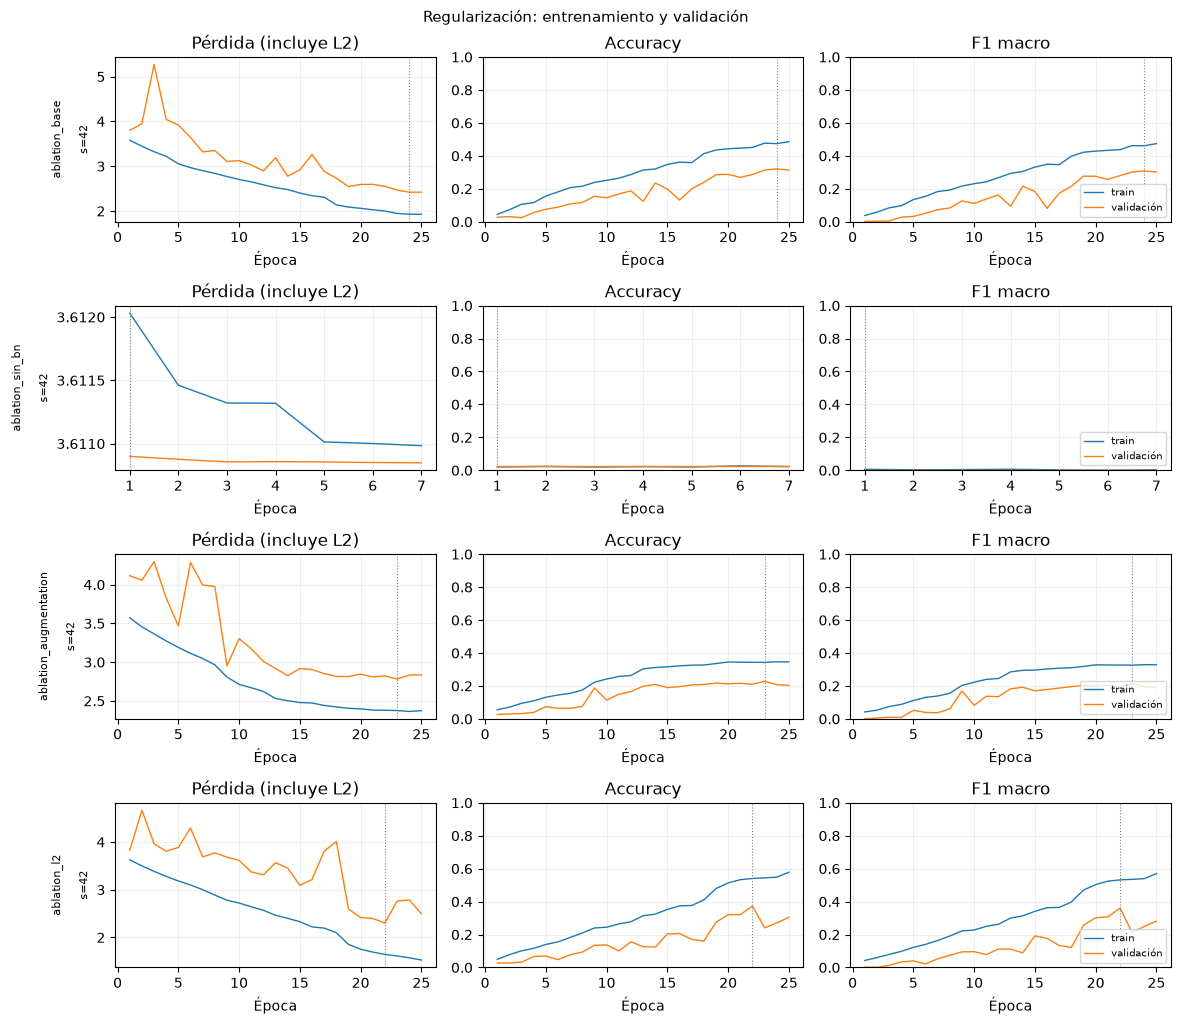

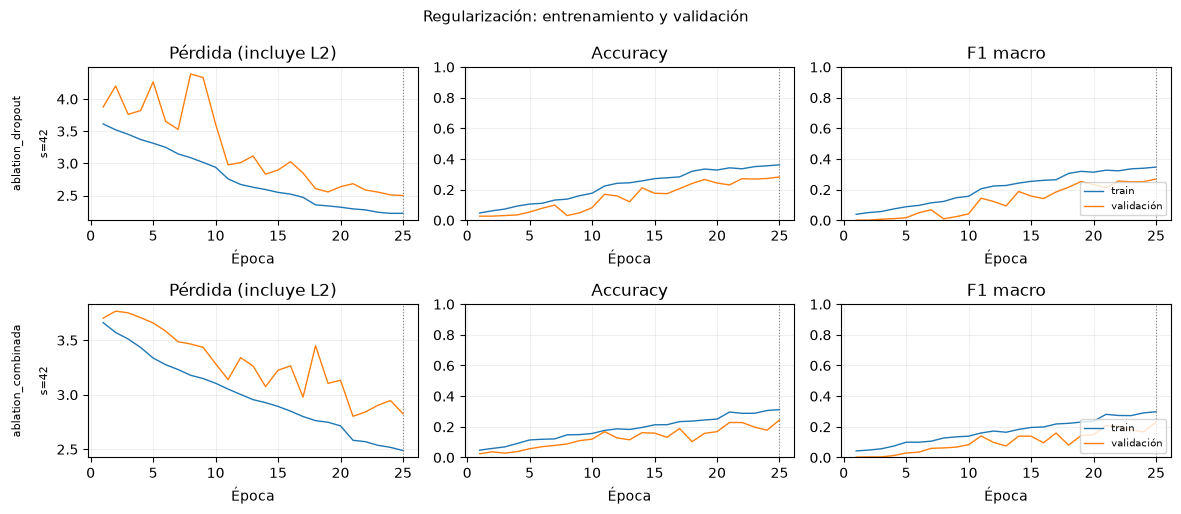

In [11]:
variants = [('base', {}), ('sin_bn', {'batch_norm': False}),
            ('augmentation', {'augmentation': True}), ('l2', {'l2': 1e-4}),
            ('dropout', {'dropout': 0.25}),
            ('combinada', {'augmentation': True, 'l2': 1e-4, 'dropout': 0.25})]
ablations = []
with ExperimentProgress('Regularización de la CNN', len(variants)) as progress:
    for name, changes in variants:
        cfg = {**baseline_config(SEED), **changes, 'stage': 'ablation_' + name}
        ablations.append(run_trial(cfg, 25, progress))
show_trials(ablations)
plot_histories(ablations, 'Regularización: entrenamiento y validación')


In [12]:
base_trial = ablations[0]
ablation_comparison = pd.DataFrame([compare_change(r, base_trial) for r in ablations[1:]])
show_table(ablation_comparison.round(4))
best_ablation = ranked_trials(ablations)[0]
display(Markdown(
    f"La mejor variante es **{best_ablation['config']['stage']}**, con F1 de validación "
    f"**{best_ablation['f1_macro']:.4f}**; la base alcanza **{base_trial['f1_macro']:.4f}**. "
    f"Su diferencia es **{best_ablation['f1_macro']-base_trial['f1_macro']:+.4f}**. "
    "Estos cambios describen esta semilla y este presupuesto. Las curvas permiten comprobar "
    "si la mejora viene acompañada de una menor brecha o si persiste el sobreajuste. "
    "Conservamos esta referencia y exploramos ahora si otra configuración la supera."))


Prueba,Referencia,F1 valid.,Δ F1,Brecha acc.,Mejor época
ablation_sin_bn,ablation_base,0.0014,-0.3066,0.0000,1
ablation_augmentation,ablation_base,0.2136,-0.0944,0.0968,23
ablation_l2,ablation_base,0.3602,0.0522,0.1841,22
ablation_dropout,ablation_base,0.2690,-0.0390,0.1535,25
ablation_combinada,ablation_base,0.2307,-0.0773,0.0890,25


La mejor variante es **ablation_l2**, con F1 de validación **0.3602**; la base alcanza **0.3080**. Su diferencia es **+0.0522**. Estos cambios describen esta semilla y este presupuesto. Las curvas permiten comprobar si la mejora viene acompañada de una menor brecha o si persiste el sobreajuste. Conservamos esta referencia y exploramos ahora si otra configuración la supera.

<a id="s6"></a>

## 6. Búsqueda de configuraciones desde cero

La regularización no responde por sí sola a la elección de capacidad y tasa de aprendizaje.
Muestreamos doce configuraciones reproducibles, variando filtros, convoluciones por bloque,
cabeza densa, aumentos, dropout, L2 y tasa inicial. Las cribamos con seis épocas,
reentrenamos las cuatro mejores hasta dieciocho y las dos mejores hasta treinta y cinco.

Cada escalón empieza desde cero. No es una continuación de pesos ni un algoritmo Hyperband.
Solo las confirmaciones finales compiten con las ablaciones por el puesto de finalista.
El cribado corto puede descartar redes que aprendan más despacio; retomaremos esa limitación
en la segunda ronda.


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · search_screen · C01 · s42,6,6,0.0825,0.0720,0.0496,0.7911
scratch · search_screen · C02 · s42,6,3,0.0353,0.0367,0.0115,0.7473
scratch · search_screen · C03 · s42,6,6,0.0887,0.0856,0.0486,1.4094
scratch · search_screen · C04 · s42,6,4,0.0740,0.0530,0.0277,0.6597
scratch · search_screen · C05 · s42,6,6,0.0696,0.0747,0.0475,0.6484
scratch · search_screen · C06 · s42,6,6,0.1389,0.1087,0.0900,1.2305
scratch · search_screen · C07 · s42,6,2,0.0323,0.0340,0.0120,0.9072
scratch · search_screen · C08 · s42,6,6,0.0893,0.0625,0.0325,1.4436
scratch · search_screen · C09 · s42,6,6,0.0591,0.0543,0.0315,0.2516
scratch · search_screen · C10 · s42,6,6,0.0829,0.0788,0.0464,0.2564


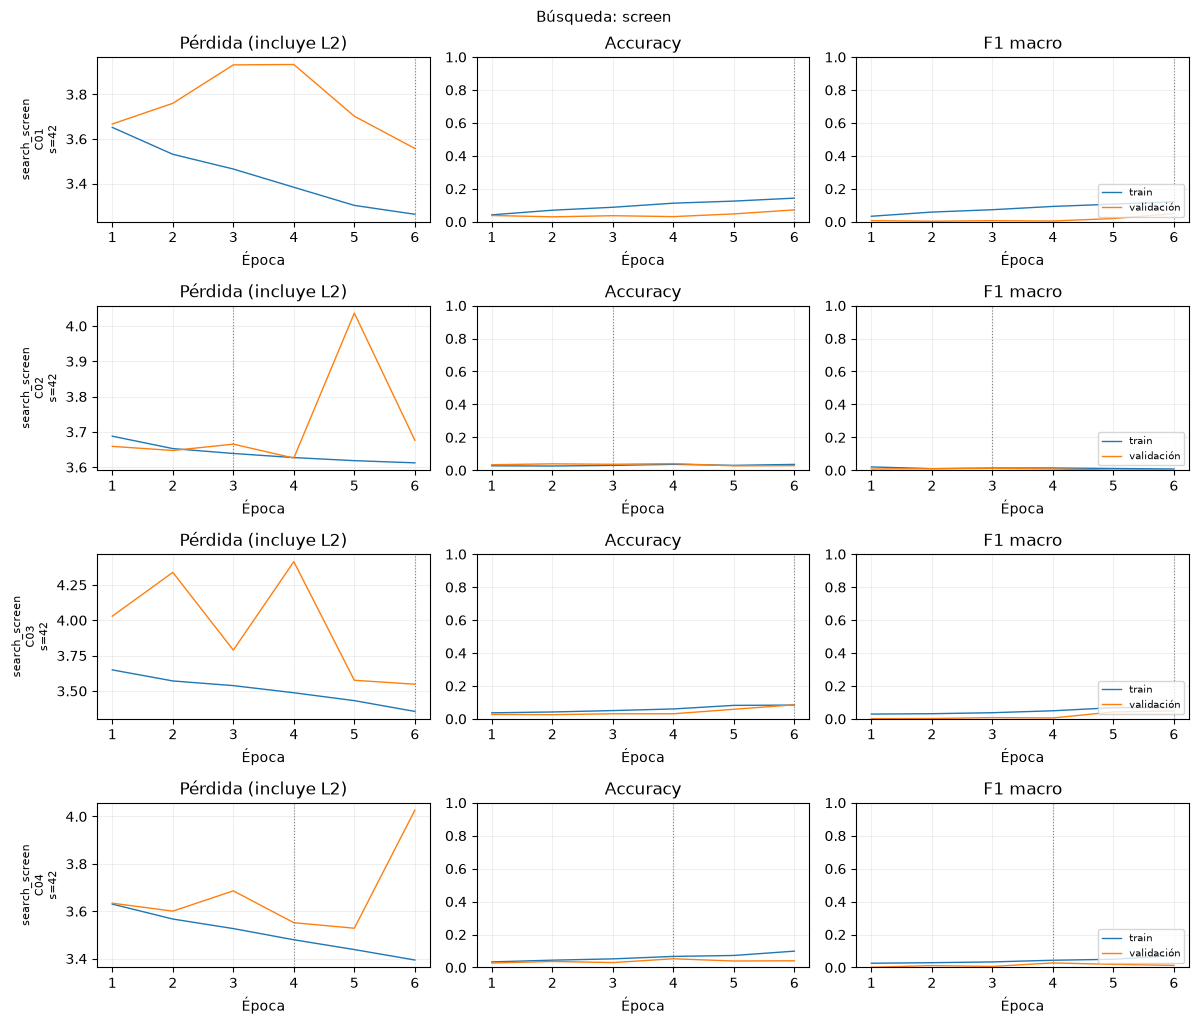

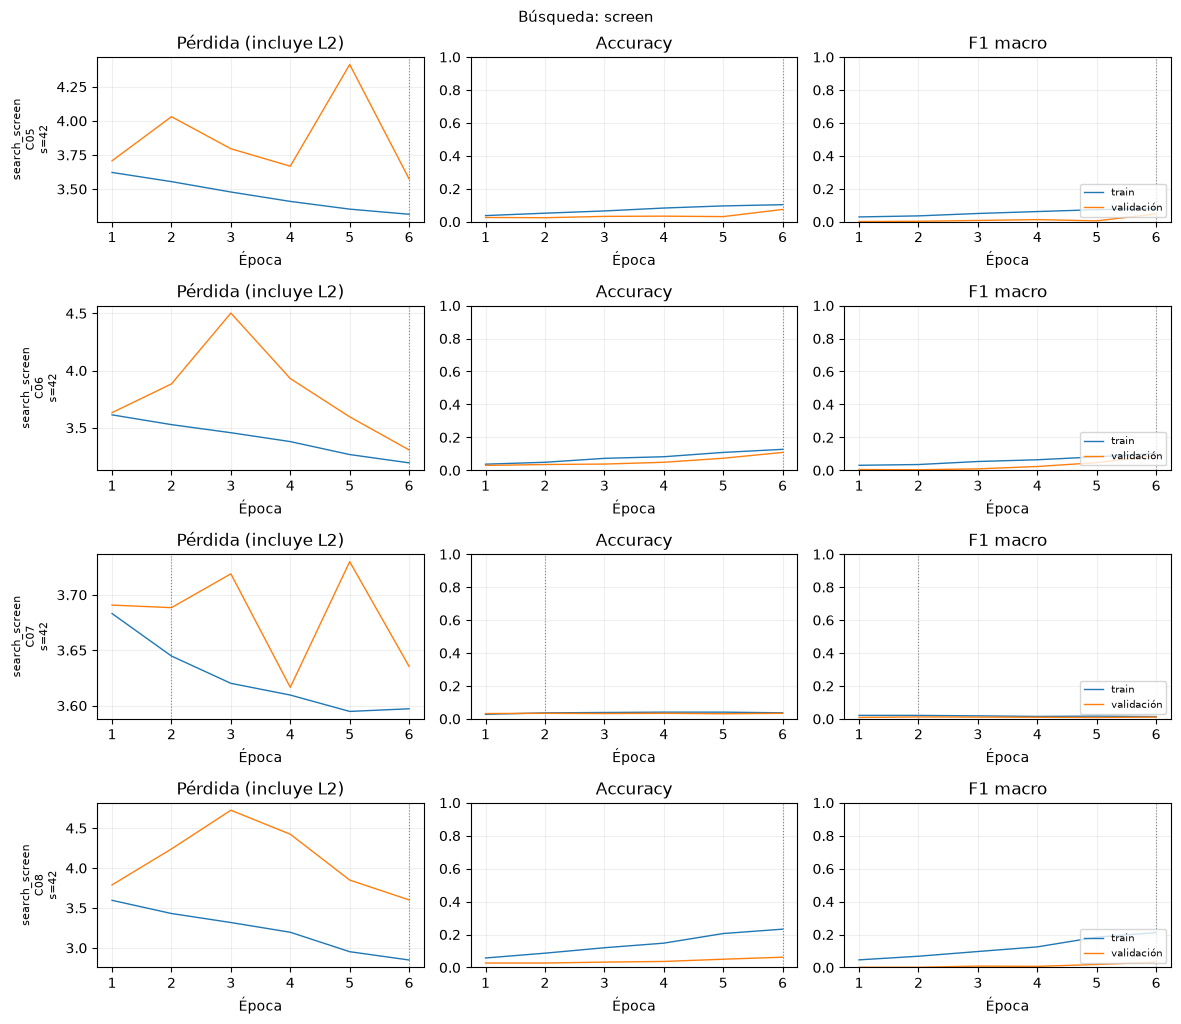

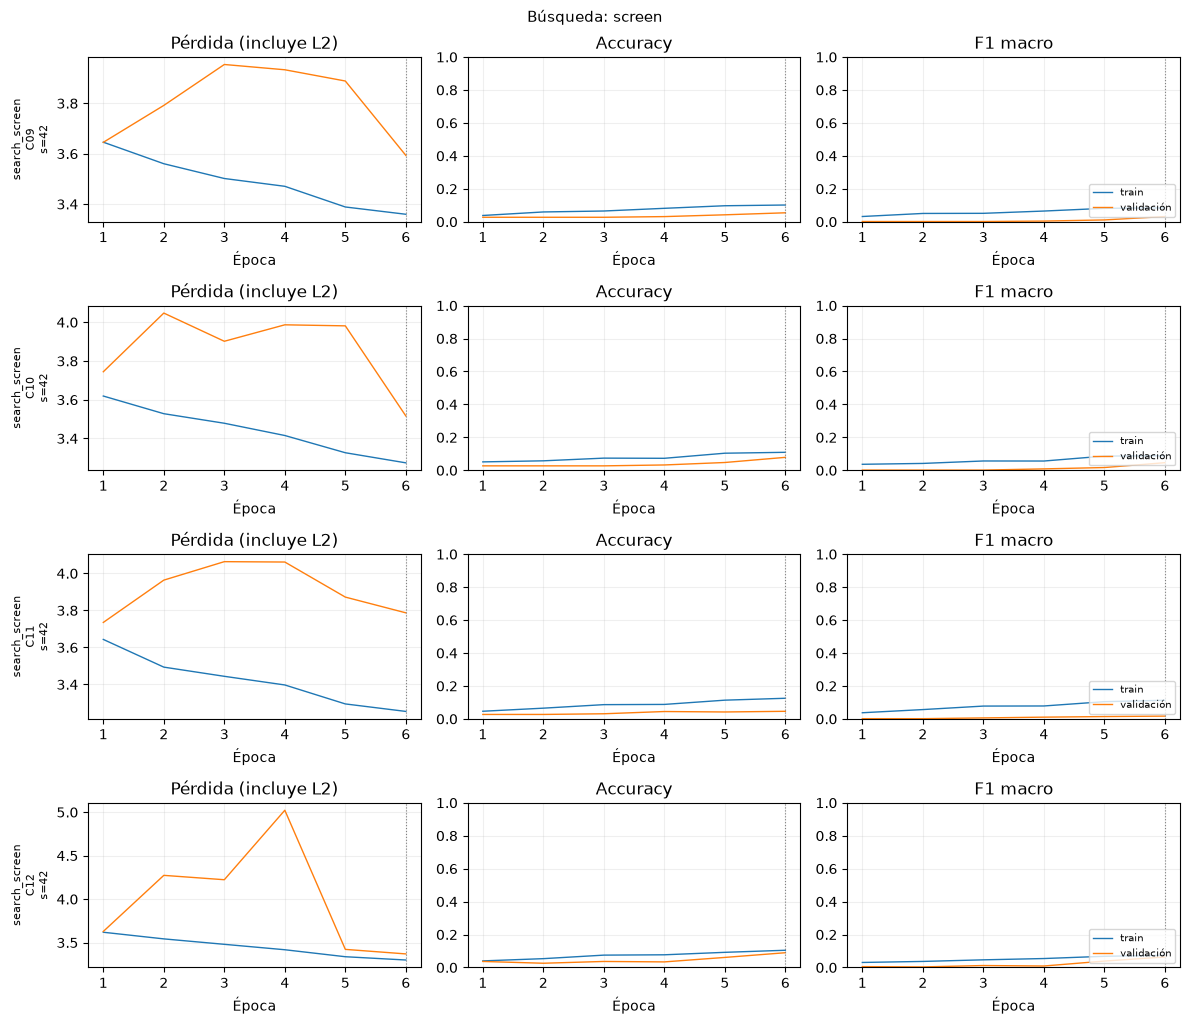

Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · search_refine · C06 · s42,18,18,0.2351,0.1522,0.1380,0.8907
scratch · search_refine · C12 · s42,18,17,0.1793,0.1359,0.1110,0.8785
scratch · search_refine · C01 · s42,18,16,0.2476,0.1467,0.1320,0.9388
scratch · search_refine · C03 · s42,18,18,0.3696,0.2500,0.2231,1.1266


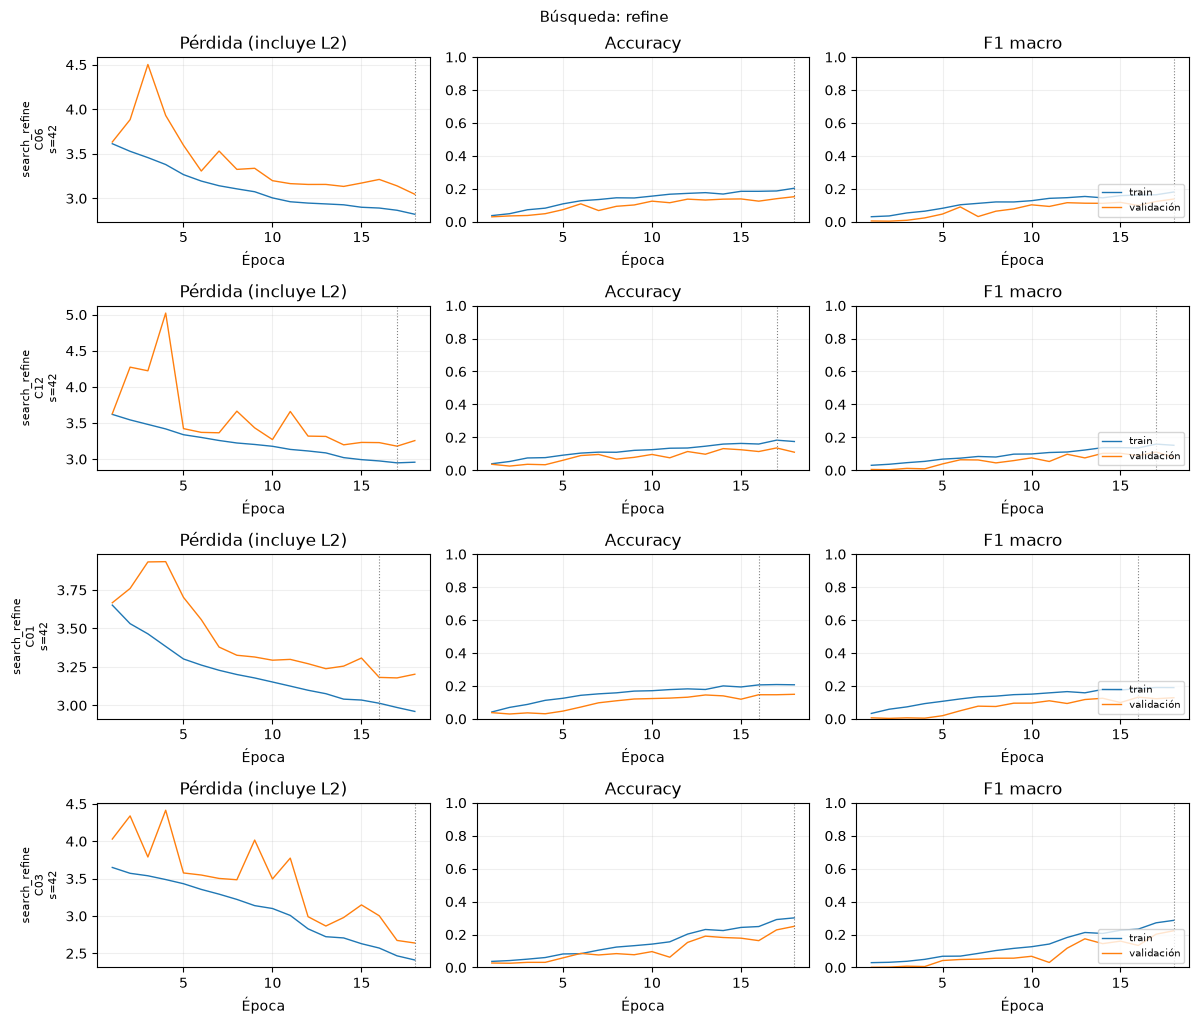

Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · search_confirm · C03 · s42,34,28,0.4789,0.3329,0.3151,2.1315
scratch · search_confirm · C06 · s42,25,19,0.2398,0.1821,0.1592,1.2434


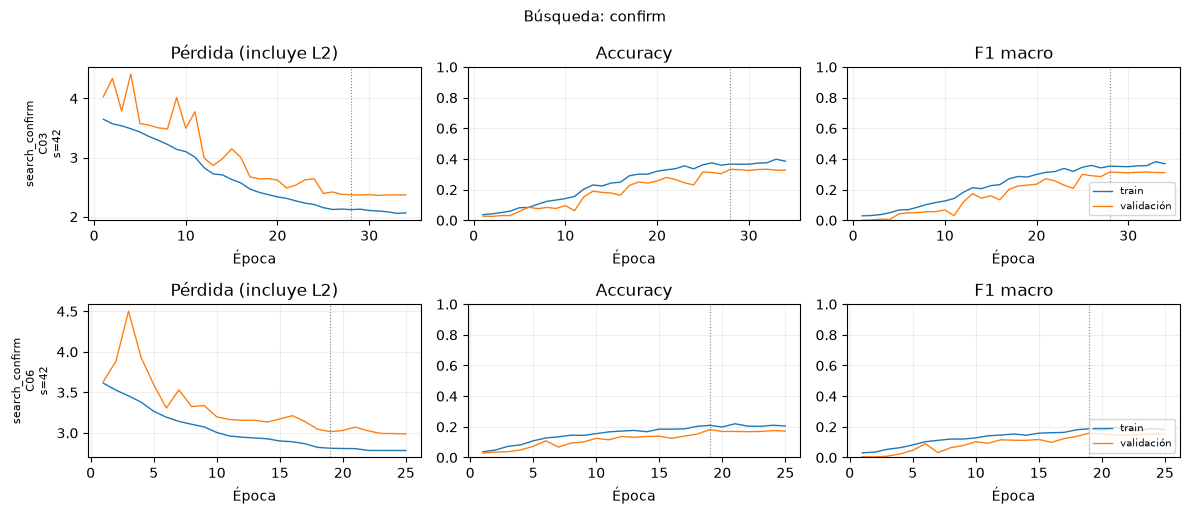

Ensayo,Filtros,Conv./bloque,Densa,BN
search_screen · C01,"[24, 48, 96]",2,128,True
search_screen · C02,"[32, 64, 128, 256]",1,64,True
search_screen · C03,"[32, 64, 128, 256]",2,128,True
search_screen · C04,"[32, 64, 128]",1,128,True
search_screen · C05,"[32, 64, 128]",1,64,True
search_screen · C06,"[24, 48, 96]",2,128,True
search_screen · C07,"[32, 64, 128, 256]",1,64,True
search_screen · C08,"[32, 64, 128, 256]",2,64,True
search_screen · C09,"[32, 64, 128]",1,128,True
search_screen · C10,"[32, 64, 128, 256]",1,64,True


Ensayo,Aumentos,Dropout,L2,LR inicial
search_screen · C01,False,0.15,0.00010,0.0003
search_screen · C02,True,0.30,0.00010,0.0030
search_screen · C03,False,0.30,0.00001,0.0010
search_screen · C04,True,0.15,0.00001,0.0030
search_screen · C05,False,0.00,0.00001,0.0030
search_screen · C06,False,0.15,0.00000,0.0030
search_screen · C07,True,0.15,0.00010,0.0030
search_screen · C08,False,0.15,0.00001,0.0003
search_screen · C09,True,0.30,0.00010,0.0010
search_screen · C10,True,0.15,0.00000,0.0010


La mejor confirmación obtiene F1 **0.3151**, frente a **0.3602** de la mejor ablación. El finalista scratch de la primera ronda es **ablation_l2** con **0.3602**. La diferencia mezcla arquitectura, hiperparámetros y presupuestos; no la atribuimos a una sola técnica.

Ensayo,Filtros,Conv./bloque,Densa,BN
ablation_l2,"[32, 64, 128]",2,128,True


Ensayo,Aumentos,Dropout,L2,LR inicial
ablation_l2,False,0.0,0.0001,0.001


In [13]:
search_results = []
configs = random_scratch_configs(count=12, seed=SEED)
configs = [{**cfg, 'candidate': f'C{i:02d}'} for i, cfg in enumerate(configs, 1)]
previous = []
for stage, epochs, keep in [('screen', 6, None), ('refine', 18, 4), ('confirm', 35, 2)]:
    if keep is not None:
        configs = [dict(r['config']) for r in ranked_trials(previous)[:keep]]
    current = []
    with ExperimentProgress('Búsqueda CNN: ' + stage, len(configs)) as progress:
        for config in configs:
            cfg = {k: v for k, v in config.items() if k != 'epochs'}
            cfg['stage'] = 'search_' + stage
            current.append(run_trial(cfg, epochs, progress))
    show_trials(current)
    plot_histories(current, 'Búsqueda: ' + stage)
    search_results.extend(current)
    previous = current

confirmed = previous
best_search = ranked_trials(confirmed)[0]
first_scratch = ranked_trials(ablations + confirmed)[0]
show_configs([r for r in search_results if r['config']['stage'] == 'search_screen'])
display(Markdown(
    f"La mejor confirmación obtiene F1 **{best_search['f1_macro']:.4f}**, frente a "
    f"**{best_ablation['f1_macro']:.4f}** de la mejor ablación. "
    f"El finalista scratch de la primera ronda es **{first_scratch['config']['stage']}** "
    f"con **{first_scratch['f1_macro']:.4f}**. "
    "La diferencia mezcla arquitectura, hiperparámetros y presupuestos; no la atribuimos a una sola técnica."))
show_configs([first_scratch])


<a id="s7"></a>

## 7. Transfer learning y ajuste fino

Comparamos dos arquitecturas diferentes. Para cada una entrenamos la cabeza durante un
máximo de doce épocas con Adam y LR 1e-3. Después probamos ocho épocas de ajuste fino:
30 capas finales y LR 1e-5 en MobileNetV2; 50 y LR 5e-6 en EfficientNetB0.
“Capas finales” incluye capas sin pesos: no equivale a ese número de convoluciones entrenables.

Ampliamos la comparación con dos tasas (3e-6 y 1e-5) y dos profundidades por arquitectura.
Cada ajuste parte de la misma cabeza, no del ajuste anterior. Conservamos la cabeza como
candidata, porque descongelar capas puede empeorar el resultado. La combinación ya ejecutada
de MobileNetV2 se reutiliza dentro de esta sesión.


Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
W0000 00:00:1795192015.748177  192820 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
Corrupt JPEG data: premature end of data segment
W0000 00:00:1795192017.823731  192899 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
E0000 00:00:1795192168.330636  156011 meta_optimizer.cc:967] layout failed: INVALID_AR

Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
mobilenet · head · s42,12,9,0.9813,0.8899,0.8882,0.6279
mobilenet · fine_tuning · 30 capas · LR 1e-05 · s42,8,6,0.9898,0.8954,0.8948,0.4769
efficientnet · head · s42,12,8,0.9803,0.9144,0.9144,0.8248
efficientnet · fine_tuning · 50 capas · LR 5e-06 · s42,8,3,0.9820,0.9212,0.9212,0.6710


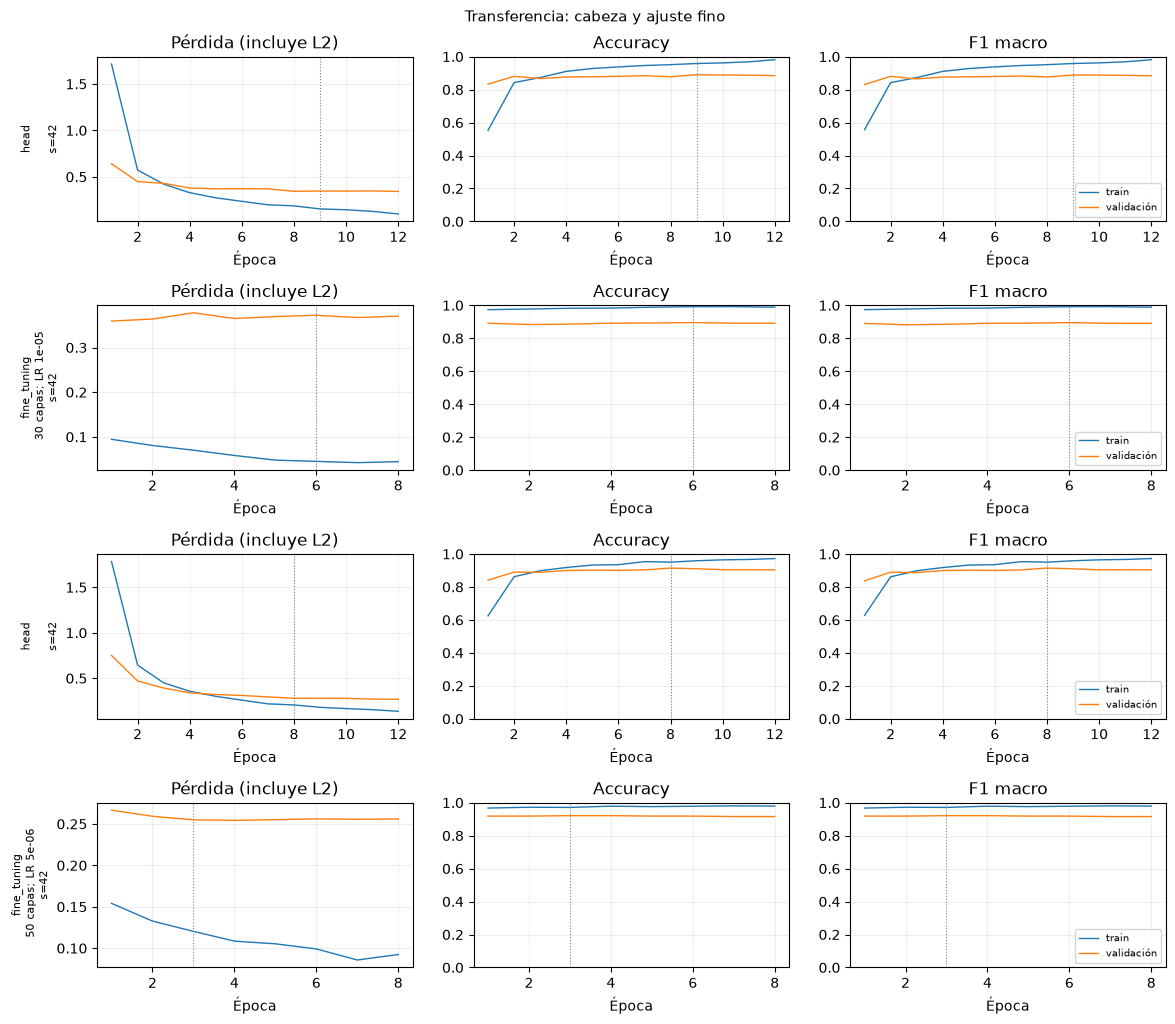

E0000 00:00:1795192346.099648  156011 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/pets_efficientnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
E0000 00:00:1795192458.148326  156011 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/pets_efficientnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
mobilenet · fine_tuning · 15 capas · LR 3e-06 · s42,8,3,0.9817,0.8899,0.8893,0.4450
mobilenet · fine_tuning · 30 capas · LR 3e-06 · s42,8,7,0.9847,0.8927,0.8921,0.4638
mobilenet · fine_tuning · 15 capas · LR 1e-05 · s42,8,6,0.9871,0.8940,0.8933,0.4540
efficientnet · fine_tuning · 20 capas · LR 3e-06 · s42,8,5,0.9817,0.9185,0.9186,0.6029
efficientnet · fine_tuning · 50 capas · LR 3e-06 · s42,8,4,0.9823,0.9185,0.9186,0.6580
efficientnet · fine_tuning · 20 capas · LR 1e-05 · s42,8,4,0.9834,0.9198,0.9200,0.6113
efficientnet · fine_tuning · 50 capas · LR 1e-05 · s42,8,2,0.9834,0.9198,0.9198,0.6747


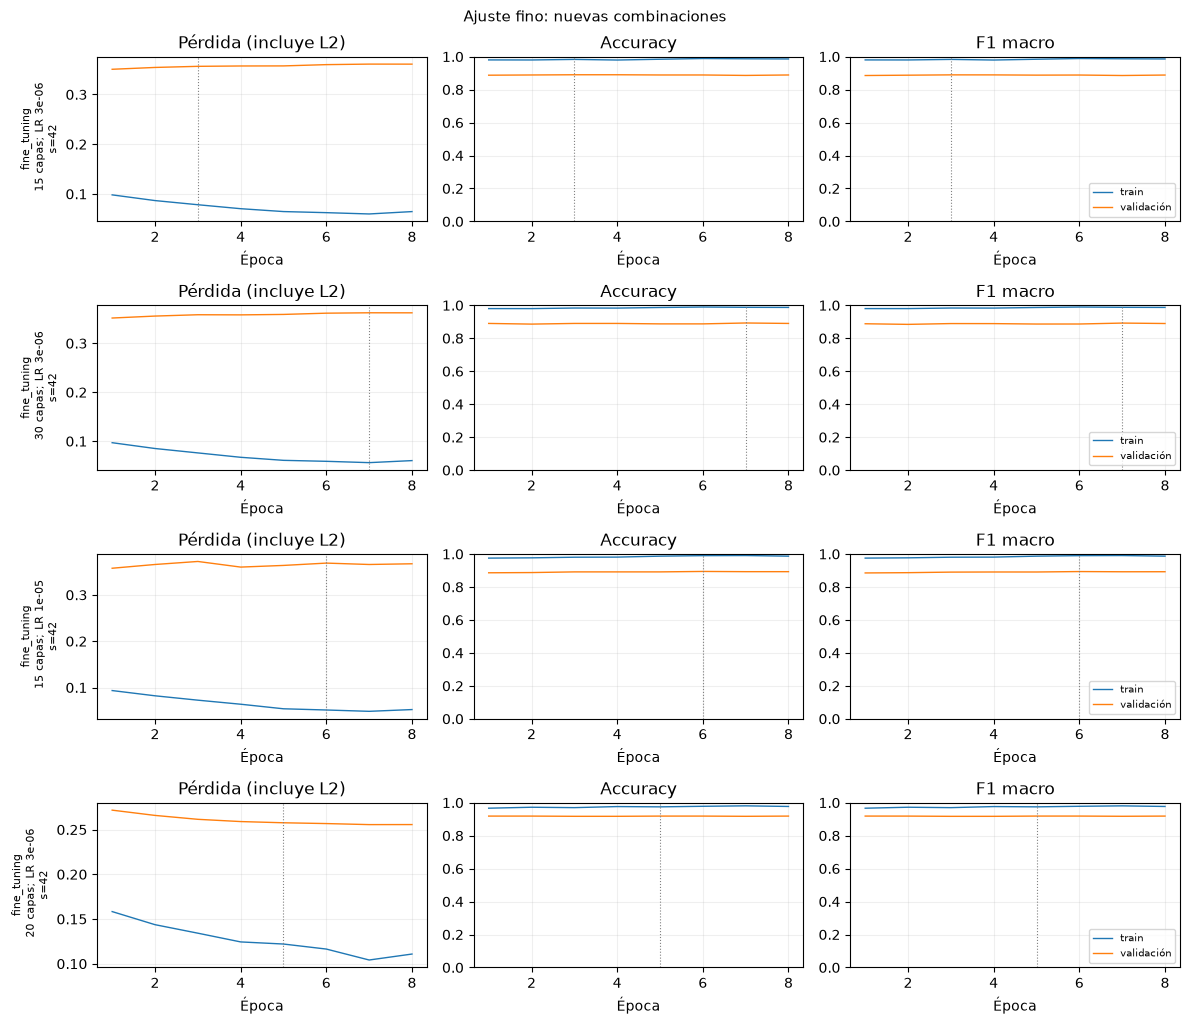

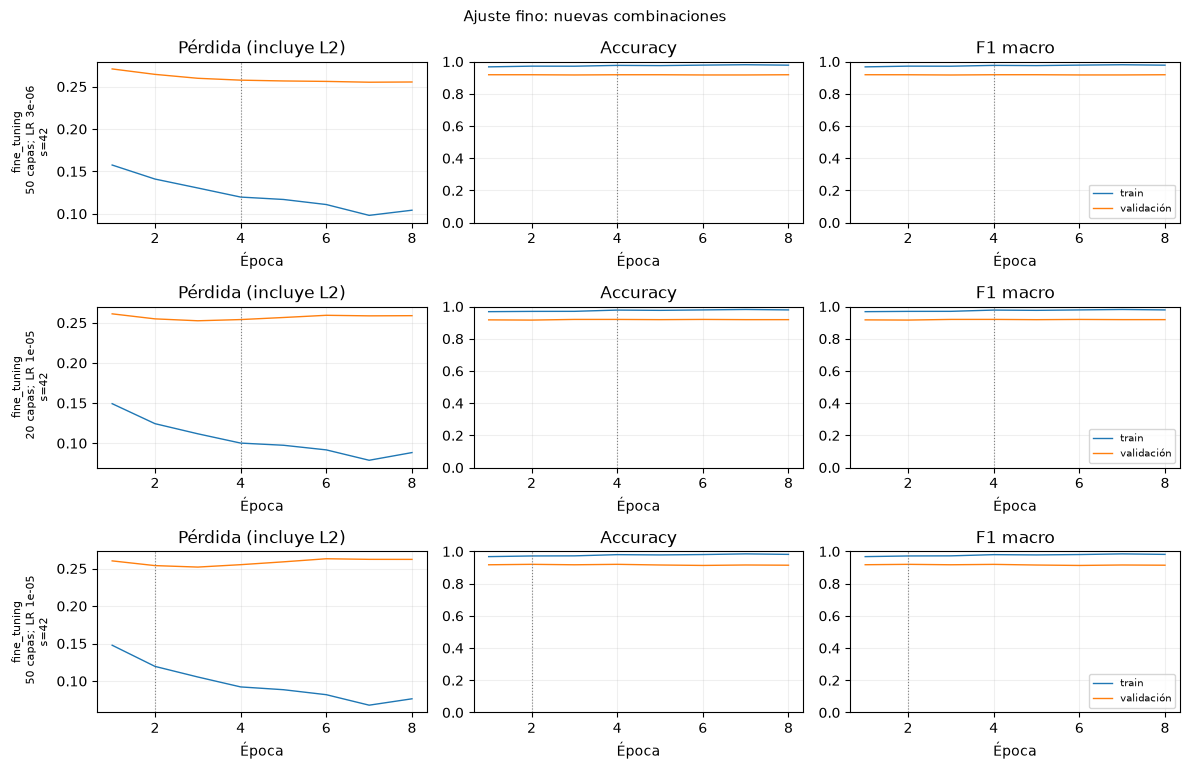

In [14]:
transfer_initial = []
heads = {}
with ExperimentProgress('Cabezas y primer ajuste fino', 4) as progress:
    for family, depth, lr in [('mobilenet', 30, 1e-5), ('efficientnet', 50, 5e-6)]:
        cfg = {'family': family, 'stage': 'head', 'size': 224, 'seed': SEED,
               'augmentation': True, 'dropout': 0.2, 'learning_rate': 1e-3,
               'batch_size': BATCH_SIZE}
        head = run_trial(cfg, 12, progress)
        heads[family] = head
        transfer_initial.append(head)
        fine_cfg = {**cfg, 'stage': 'fine_tuning', 'learning_rate': lr, 'unfreeze_layers': depth}
        transfer_initial.append(run_trial(fine_cfg, 8, progress, warm_start=head))
show_trials(transfer_initial)
plot_histories(transfer_initial, 'Transferencia: cabeza y ajuste fino')

transfer_grid = []
with ExperimentProgress('Tasas y profundidad del ajuste fino', 8) as progress:
    for family, depths in [('mobilenet', [15, 30]), ('efficientnet', [20, 50])]:
        head = heads[family]
        for lr in [3e-6, 1e-5]:
            for depth in depths:
                cfg = {**head['config'], 'stage': 'fine_tuning',
                       'learning_rate': lr, 'unfreeze_layers': depth}
                cfg.pop('epochs')
                transfer_grid.append(run_trial(cfg, 8, progress, warm_start=head))
initial_ids = {r['trial_id'] for r in transfer_initial}
new_adjustments = [r for r in transfer_grid if r['trial_id'] not in initial_ids]
show_trials(new_adjustments)
plot_histories(new_adjustments, 'Ajuste fino: nuevas combinaciones')
transfer_trials = list({r['trial_id']: r for r in transfer_initial + transfer_grid}.values())


In [15]:
transfer_comparison = []
for r in transfer_trials:
    if r['config']['stage'] == 'head':
        continue
    head = heads[r['config']['family']]
    transfer_comparison.append({'Red': r['config']['family'],
        'Capas finales': r['config']['unfreeze_layers'], 'LR inicial': r['config']['learning_rate'],
        'F1 valid.': r['f1_macro'], 'Δ F1 vs cabeza': r['f1_macro'] - head['f1_macro'],
        'Δ CE vs cabeza': r['cross_entropy'] - head['cross_entropy']})
show_table(pd.DataFrame(transfer_comparison).round(6))
transfer_finalists = [ranked_trials([r for r in transfer_trials if r['config']['family'] == family])[0]
                      for family in ['mobilenet', 'efficientnet']]
for r in transfer_finalists:
    head = heads[r['config']['family']]
    display(Markdown(
        f"Para **{r['config']['family']}** elegimos **{r['config']['stage']}**: "
        f"F1 de validación **{r['f1_macro']:.4f}**, diferencia "
        f"**{r['f1_macro']-head['f1_macro']:+.4f}** frente a la cabeza congelada. "
        "La tabla conserva también la entropía cruzada: mejorar F1 no implica mejorar todas las métricas."))


Red,Capas finales,LR inicial,F1 valid.,Δ F1 vs cabeza,Δ CE vs cabeza
mobilenet,30,0.000010,0.894822,0.006605,0.025427
efficientnet,50,0.000005,0.921152,0.006735,-0.025267
mobilenet,15,0.000003,0.889280,0.001063,0.009735
mobilenet,30,0.000003,0.892110,0.003893,0.015492
mobilenet,15,0.000010,0.893327,0.005110,0.021789
efficientnet,20,0.000003,0.918587,0.004170,-0.022578
efficientnet,50,0.000003,0.918587,0.004170,-0.022585
efficientnet,20,0.000010,0.919969,0.005552,-0.026214
efficientnet,50,0.000010,0.919783,0.005366,-0.026300


Para **mobilenet** elegimos **fine_tuning**: F1 de validación **0.8948**, diferencia **+0.0066** frente a la cabeza congelada. La tabla conserva también la entropía cruzada: mejorar F1 no implica mejorar todas las métricas.

Para **efficientnet** elegimos **fine_tuning**: F1 de validación **0.9212**, diferencia **+0.0067** frente a la cabeza congelada. La tabla conserva también la entropía cruzada: mejorar F1 no implica mejorar todas las métricas.

<a id="s8"></a>

## 8. Balance de la primera ronda y semillas

Repetimos el ganador de cada familia con semillas 123 y 2026, manteniendo la configuración,
la partición y el presupuesto. Si se ha elegido un ajuste fino, cada repetición entrena
primero su propia cabeza: no hereda los pesos de la semilla 42.

La media y la desviación típica muestral ayudan a ver si la comparación depende mucho
de la inicialización y del orden de entrenamiento. Tres semillas no demuestran significación
estadística ni sustituyen una comparación con otras particiones.


E0000 00:00:1795192847.767288  156011 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/pets_efficientnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
E0000 00:00:1795193185.719074  156011 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/pets_efficientnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · repeat_scratch · s123,25,25,0.4854,0.3003,0.2927,1.4856
mobilenet · repeat_head · s123,12,9,0.9786,0.9049,0.9047,0.5853
mobilenet · repeat_fine_tuning · 30 capas · LR 1e-05 · s123,8,5,0.9847,0.9022,0.9013,0.4595
efficientnet · repeat_head · s123,12,11,0.9868,0.9185,0.9182,0.8287
efficientnet · repeat_fine_tuning · 50 capas · LR 5e-06 · s123,8,3,0.9868,0.9185,0.9185,0.6663
scratch · repeat_scratch · s2026,25,24,0.4494,0.2758,0.2619,1.3872
mobilenet · repeat_head · s2026,12,9,0.9755,0.9062,0.9061,0.5812
mobilenet · repeat_fine_tuning · 30 capas · LR 1e-05 · s2026,8,2,0.9827,0.9062,0.9062,0.4646
efficientnet · repeat_head · s2026,12,12,0.9864,0.9130,0.9127,0.8552
efficientnet · repeat_fine_tuning · 50 capas · LR 5e-06 · s2026,8,3,0.9878,0.9171,0.9167,0.6583


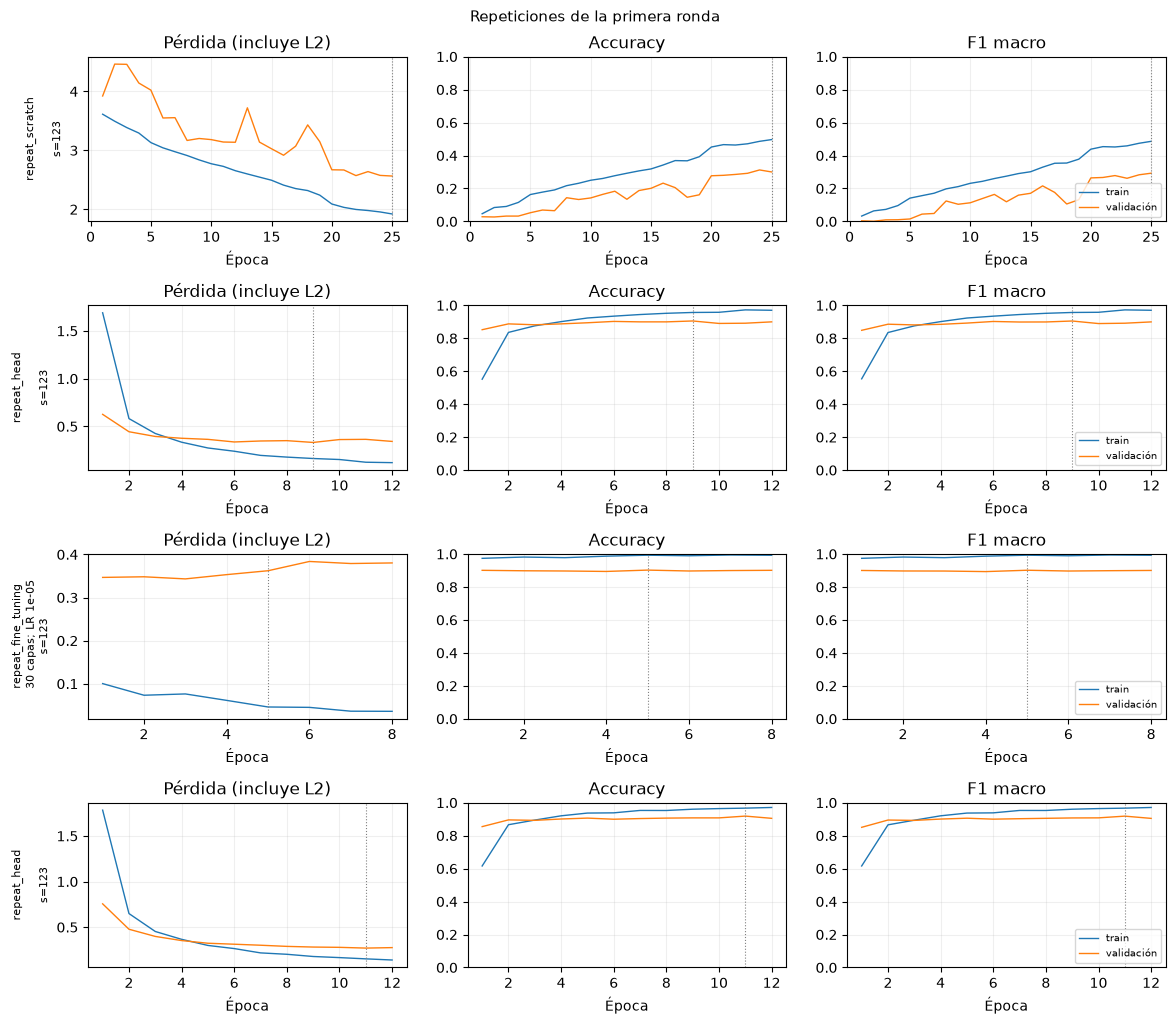

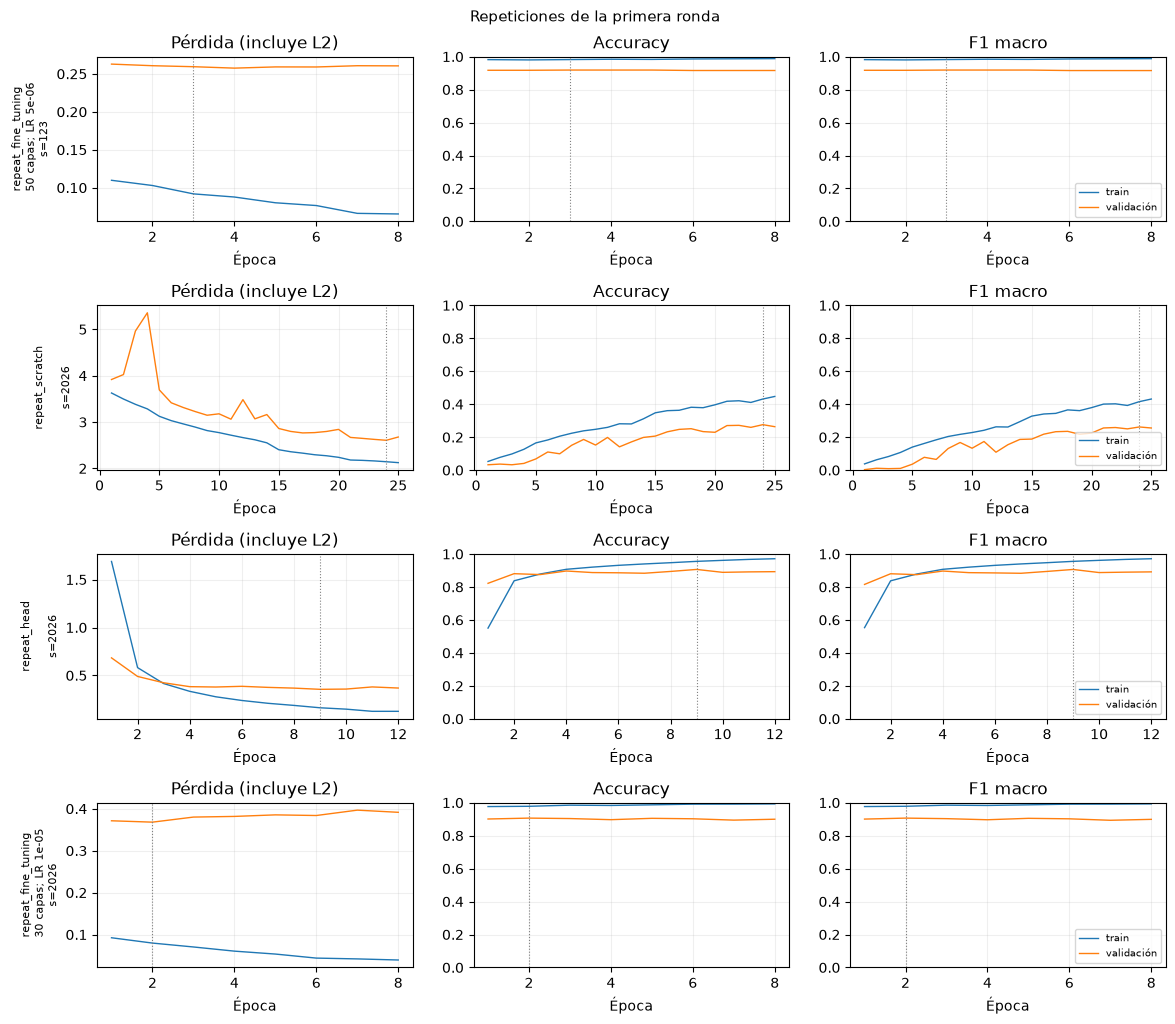

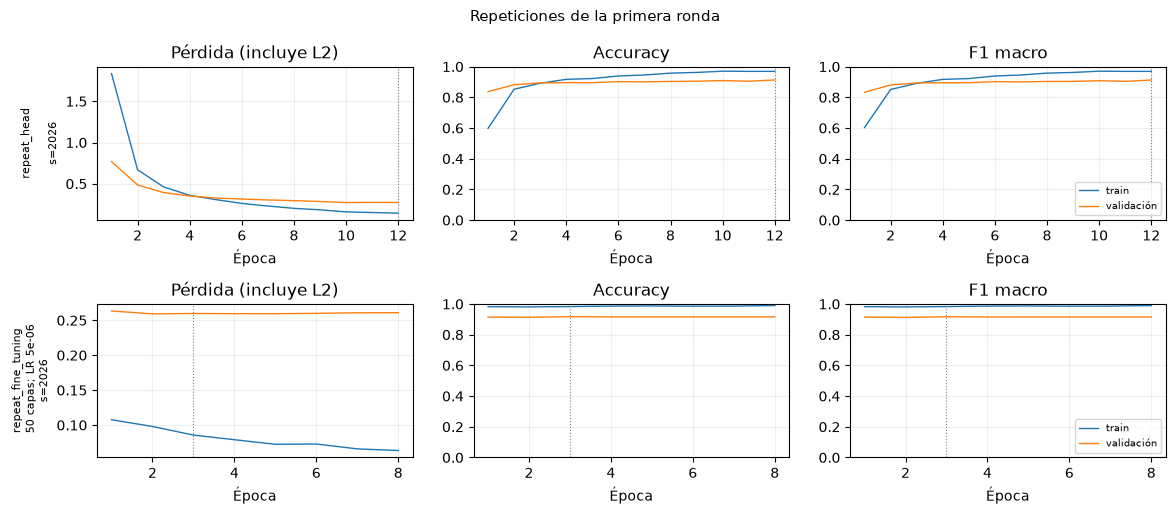

Familia,Semilla,F1 valid.
scratch,42,0.3602
scratch,123,0.2927
scratch,2026,0.2619
mobilenet,42,0.8948
mobilenet,123,0.9013
mobilenet,2026,0.9062
efficientnet,42,0.9212
efficientnet,123,0.9185
efficientnet,2026,0.9167


,Semillas,Media,Desv. típica
Familia,,,
efficientnet,3,0.9188,0.0022
mobilenet,3,0.9008,0.0057
scratch,3,0.3049,0.0503


La primera ronda contiene **45 entrenamientos distintos**. El finalista scratch tiene una brecha train–validación de **+18.41%** y F1 medio entre semillas **0.3049** (desviación **0.0503**). Esto nos lleva a examinar conjuntamente el presupuesto, la parada y la capacidad de generalizar. No asumimos que entrenar más vaya a mejorar el resultado.

In [16]:
first_finalists = [first_scratch] + transfer_finalists
repetitions_first = {r['config']['family']: [r] for r in first_finalists}
new_repetition_trials = []
total_repetitions = 2 * sum(1 if r['config']['family'] == 'scratch' or r['config']['stage'] == 'head'
                            else 2 for r in first_finalists)
with ExperimentProgress('Semillas de la primera ronda', total_repetitions) as progress:
    for seed in [123, 2026]:
        for original in first_finalists:
            cfg = {**original['config'], 'seed': seed}
            epochs = cfg.pop('epochs')
            family = cfg['family']
            if family == 'scratch':
                cfg['stage'] = 'repeat_scratch'
                trial = run_trial(cfg, epochs, progress)
            else:
                head_cfg = {**heads[family]['config'], 'seed': seed, 'stage': 'repeat_head'}
                head_epochs = head_cfg.pop('epochs')
                head = run_trial(head_cfg, head_epochs, progress)
                new_repetition_trials.append(head)
                if original['config']['stage'] == 'head':
                    trial = head
                else:
                    cfg['stage'] = 'repeat_fine_tuning'
                    trial = run_trial(cfg, epochs, progress, warm_start=head)
            repetitions_first[family].append(trial)
            if trial not in new_repetition_trials:
                new_repetition_trials.append(trial)
show_trials(new_repetition_trials)
plot_histories(new_repetition_trials, 'Repeticiones de la primera ronda')

def seed_summary(groups):
    rows = [{'Familia': family, 'Semilla': r['config']['seed'], 'F1 valid.': r['f1_macro']}
            for family, trials in groups.items() for r in trials]
    table = pd.DataFrame(rows)
    show_table(table.round(4))
    summary = table.groupby('Familia')['F1 valid.'].agg(['count', 'mean', 'std'])
    display(summary.rename(columns={'count': 'Semillas', 'mean': 'Media', 'std': 'Desv. típica'}).round(4))
    return summary

first_seed_stats = seed_summary(repetitions_first)
first_round_trials = list(TRIALS.values())
gap = first_scratch['train_accuracy_clean'] - first_scratch['accuracy']
display(Markdown(
    f"La primera ronda contiene **{len(first_round_trials)} entrenamientos distintos**. "
    f"El finalista scratch tiene una brecha train–validación de **{gap:+.2%}** "
    f"y F1 medio entre semillas **{first_seed_stats.loc['scratch', 'mean']:.4f}** "
    f"(desviación **{first_seed_stats.loc['scratch', 'std']:.4f}**). "
    "Esto nos lleva a examinar conjuntamente el presupuesto, la parada y la capacidad de generalizar. "
    "No asumimos que entrenar más vaya a mejorar el resultado."))


<a id="s9"></a>

## 9. Segunda ronda: presupuesto, política y capacidad

Retomamos la mejor CNN de la primera ronda. Primero aumentamos el máximo a 80 épocas,
manteniendo la política inicial. Después probamos una política más paciente: quince épocas
sin mejora para detenerse y cinco para reducir LR, guiada ahora por F1 de validación.
Este segundo cambio compara un conjunto de decisiones, no el efecto aislado de una paciencia.

Bajo la política paciente cambiamos por separado LR, aumentos, dropout y profundidad.
Los valores se eligen de forma que difieran de la referencia si esta ha cambiado al repetir
el estudio. También recuperamos el mejor candidato confirmado de la búsqueda para revisar
la limitación del cribado corto. En esa recuperación pueden cambiar varios hiperparámetros;
no se interpreta como una ablación.

Las siete pruebas empiezan desde cero, con semilla 42. Si ninguna mejora la referencia,
conservamos el finalista de la primera ronda.


Ensayo,Filtros,Conv./bloque,Densa,BN
round2_long_original,"[32, 64, 128]",2,128,True
round2_long_patient,"[32, 64, 128]",2,128,True
round2_lower_lr,"[32, 64, 128]",2,128,True
round2_augmentation,"[32, 64, 128]",2,128,True
round2_dropout,"[32, 64, 128]",2,128,True
round2_capacity,"[32, 64, 128, 256]",2,128,True
round2_prior_search · C03,"[32, 64, 128, 256]",2,128,True


Ensayo,Aumentos,Dropout,L2,LR inicial
round2_long_original,False,0.00,0.00010,0.0010
round2_long_patient,False,0.00,0.00010,0.0010
round2_lower_lr,False,0.00,0.00010,0.0003
round2_augmentation,True,0.00,0.00010,0.0010
round2_dropout,False,0.15,0.00010,0.0010
round2_capacity,False,0.00,0.00010,0.0010
round2_prior_search · C03,False,0.30,0.00001,0.0010


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · round2_long_original · s42,55,49,0.7238,0.4293,0.4172,3.1641
scratch · round2_long_patient · s42,76,61,0.8424,0.4470,0.4370,4.1463
scratch · round2_lower_lr · s42,60,45,0.7082,0.3614,0.3528,3.2491
scratch · round2_augmentation · s42,54,39,0.5014,0.3465,0.3362,3.0163
scratch · round2_dropout · s42,54,39,0.6827,0.4239,0.4178,3.0626
scratch · round2_capacity · s42,58,43,0.9813,0.4321,0.4262,3.5333
scratch · round2_prior_search · C03 · s42,70,55,0.9660,0.4647,0.4605,4.2823


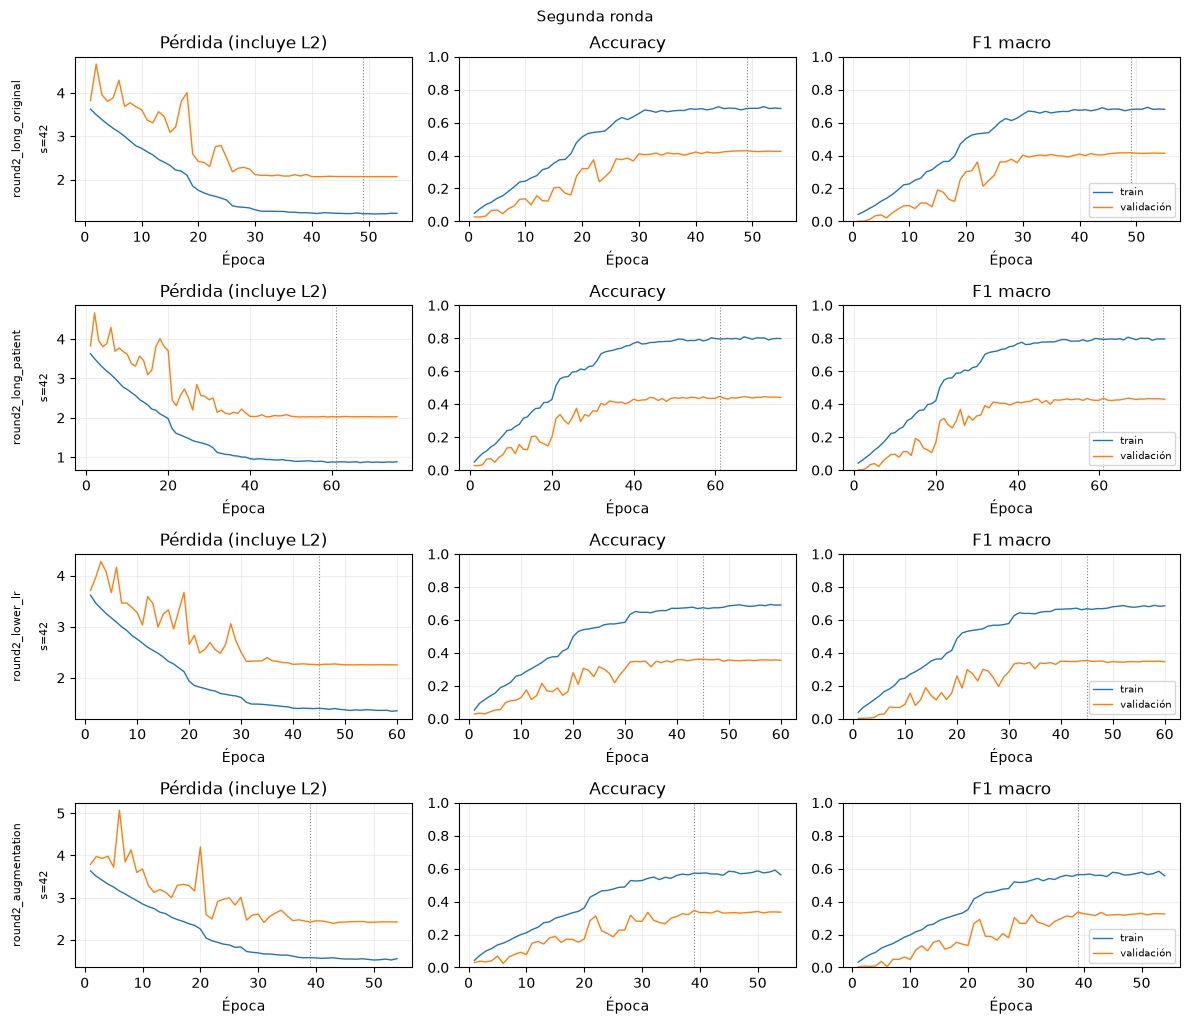

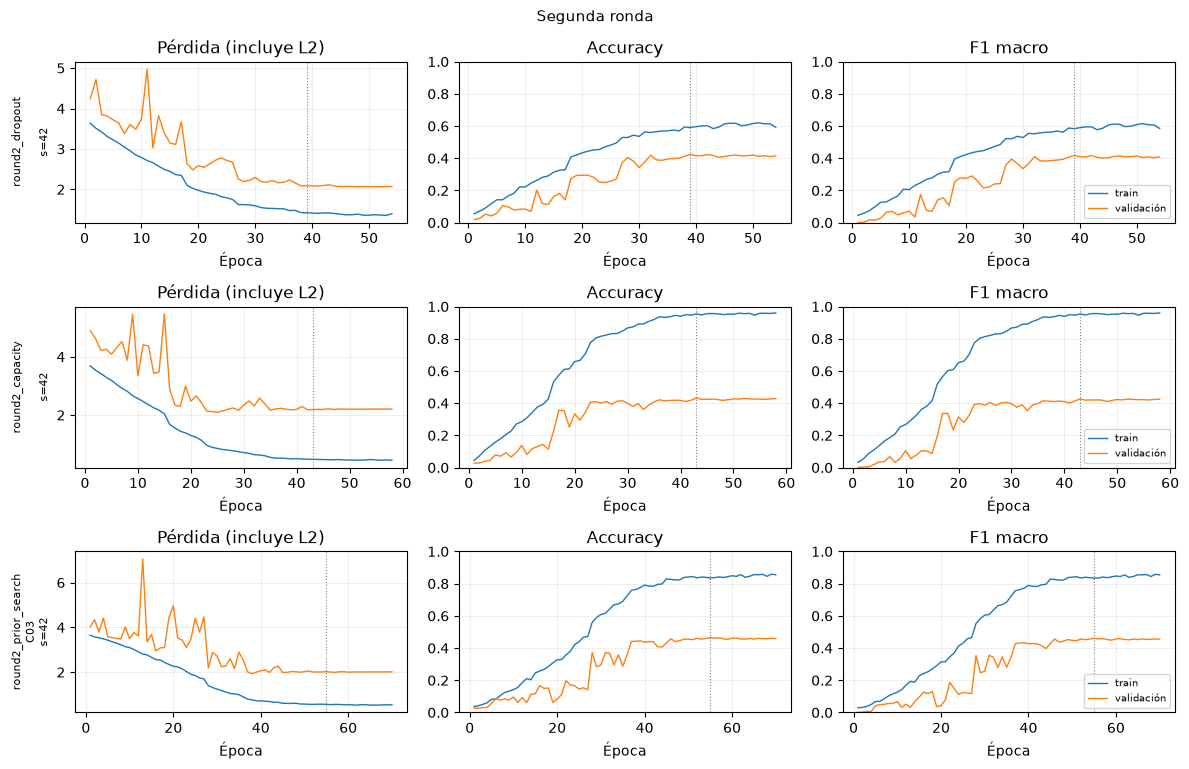

In [17]:
base = {k: v for k, v in first_scratch['config'].items() if k not in ['epochs', 'stage']}
base['policy'] = 'patient_f1'
alternative_lr = 3e-4 if base['learning_rate'] != 3e-4 else 1e-4
alternative_dropout = 0.15 if base.get('dropout', 0) != 0.15 else 0.30
larger_filters = base['filters'] + [min(512, 2 * base['filters'][-1])]
specs = [('long_original', {'policy': 'original'}), ('long_patient', {}),
         ('lower_lr', {'learning_rate': alternative_lr}),
         ('augmentation', {'augmentation': not base.get('augmentation', False)}),
         ('dropout', {'dropout': alternative_dropout}), ('capacity', {'filters': larger_filters})]
round2_configs = [{**base, **changes, 'stage': 'round2_' + name} for name, changes in specs]
prior_cfg = {k: v for k, v in best_search['config'].items() if k not in ['epochs', 'stage']}
round2_configs.append({**prior_cfg, 'policy': 'patient_f1', 'stage': 'round2_prior_search'})
# El plan se muestra antes de iniciar los entrenamientos.
show_configs([{'config': c} for c in round2_configs])
new_trials = []
with ExperimentProgress('Segunda ronda de CNN', len(round2_configs)) as progress:
    for cfg in round2_configs:
        new_trials.append(run_trial(cfg, 80, progress))
show_trials(new_trials)
plot_histories(new_trials, 'Segunda ronda')


In [18]:
by_stage = {r['config']['stage']: r for r in new_trials}
long_original = by_stage['round2_long_original']
patient = by_stage['round2_long_patient']
changes = []
for r in new_trials:
    reference = first_scratch if r is long_original else long_original if r is patient else patient
    changes.append(compare_change(r, reference))
show_table(pd.DataFrame(changes).round(4))
selected_scratch = ranked_trials([first_scratch] + new_trials)[0]
display(Markdown(
    f"Ampliar el presupuesto con la política original cambia el F1 en "
    f"**{long_original['f1_macro']-first_scratch['f1_macro']:+.4f}**. "
    f"La política paciente añade **{patient['f1_macro']-long_original['f1_macro']:+.4f}** "
    "frente a esa referencia ampliada. Son comparaciones diferentes y no deben sumarse como "
    "efectos independientes de cada callback."))
recovered = by_stage['round2_prior_search']
display(Markdown(
    f"El candidato recuperado pasa de **{best_search['f1_macro']:.4f}** en su confirmación "
    f"a **{recovered['f1_macro']:.4f}** con el nuevo presupuesto y política. "
    "Esto informa sobre ese candidato, pero no demuestra qué habrían logrado todos los descartados."))
display(Markdown(
    f"Elegimos **{selected_scratch['config']['stage']}**, con F1 de validación "
    f"**{selected_scratch['f1_macro']:.4f}** y diferencia "
    f"**{selected_scratch['f1_macro']-first_scratch['f1_macro']:+.4f}** frente al finalista anterior. "
    f"Se entrenó durante **{selected_scratch['epochs_run']} épocas** y se conserva la época "
    f"**{selected_scratch['best_epoch']}**. "
    "La configuración elegida se muestra completa antes de repetirla con otras semillas."))
show_configs([selected_scratch])


Prueba,Referencia,F1 valid.,Δ F1,Brecha acc.,Mejor época
round2_long_original,ablation_l2,0.4172,0.0570,0.2945,49
round2_long_patient,round2_long_original,0.4370,0.0198,0.3954,61
round2_lower_lr,round2_long_patient,0.3528,-0.0842,0.3468,45
round2_augmentation,round2_long_patient,0.3362,-0.1008,0.1549,39
round2_dropout,round2_long_patient,0.4178,-0.0192,0.2588,39
round2_capacity,round2_long_patient,0.4262,-0.0109,0.5493,43
round2_prior_search,round2_long_patient,0.4605,0.0235,0.5014,55


Ampliar el presupuesto con la política original cambia el F1 en **+0.0570**. La política paciente añade **+0.0198** frente a esa referencia ampliada. Son comparaciones diferentes y no deben sumarse como efectos independientes de cada callback.

El candidato recuperado pasa de **0.3151** en su confirmación a **0.4605** con el nuevo presupuesto y política. Esto informa sobre ese candidato, pero no demuestra qué habrían logrado todos los descartados.

Elegimos **round2_prior_search**, con F1 de validación **0.4605** y diferencia **+0.1004** frente al finalista anterior. Se entrenó durante **70 épocas** y se conserva la época **55**. La configuración elegida se muestra completa antes de repetirla con otras semillas.

Ensayo,Filtros,Conv./bloque,Densa,BN
round2_prior_search · C03,"[32, 64, 128, 256]",2,128,True


Ensayo,Aumentos,Dropout,L2,LR inicial
round2_prior_search · C03,False,0.3,0.00001,0.001


<a id="s10"></a>

## 10. Repeticiones y elección antes de test

Si la segunda ronda cambia el ganador scratch, repetimos su configuración con semillas
123 y 2026. Si no lo cambia, usamos las repeticiones ya calculadas. Las redes preentrenadas
mantienen la selección y las semillas de la primera ronda.

La tabla de selección aparece aquí, antes de evaluar test. Incluye la configuración y la
mejor época de cada finalista. El modelo preferido se elige por validación, no por el resultado
que obtenga después en test. Los pesos seleccionados se identifican en memoria para comprobar
que sean los mismos durante la evaluación, sin generar archivos de resultados adicionales.


Modelo / ensayo,Épocas,Mejor época,Acc. train,Acc. valid.,F1 valid.,Minutos
scratch · round2_prior_search_repeat · C03 · s123,80,76,1.0000,0.4674,0.4688,5.0713
scratch · round2_prior_search_repeat · C03 · s2026,76,61,0.9504,0.4130,0.4133,4.6071


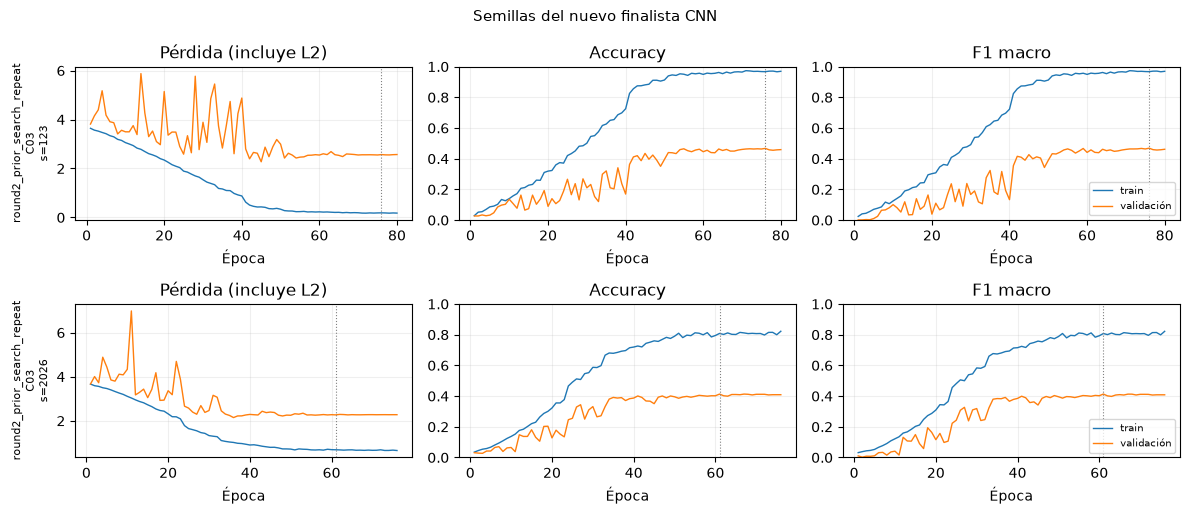

Familia,Semilla,F1 valid.
scratch,42,0.4605
scratch,123,0.4688
scratch,2026,0.4133
mobilenet,42,0.8948
mobilenet,123,0.9013
mobilenet,2026,0.9062
efficientnet,42,0.9212
efficientnet,123,0.9185
efficientnet,2026,0.9167


,Semillas,Media,Desv. típica
Familia,,,
efficientnet,3,0.9188,0.0022
mobilenet,3,0.9008,0.0057
scratch,3,0.4475,0.0299


Red,Ensayo,Semilla,Mejor época,F1 valid.,Capas ajustadas,LR inicial
scratch,round2_prior_search,42,55,0.460538,—,0.001000
mobilenet,fine_tuning,42,6,0.894822,30,0.000010
efficientnet,fine_tuning,42,3,0.921152,50,0.000005


Selección fijada: **2026-11-20T18:24:28+01:00**. Modelo preferido por validación: **efficientnet**.

In [19]:
if selected_scratch['trial_id'] == first_scratch['trial_id']:
    scratch_repetitions = repetitions_first['scratch']
else:
    scratch_repetitions = [selected_scratch]
    with ExperimentProgress('Semillas del nuevo finalista CNN', 2) as progress:
        for seed in [123, 2026]:
            cfg = {**selected_scratch['config'], 'seed': seed,
                   'stage': selected_scratch['config']['stage'] + '_repeat'}
            epochs = cfg.pop('epochs')
            scratch_repetitions.append(run_trial(cfg, epochs, progress))
    show_trials(scratch_repetitions[1:])
    plot_histories(scratch_repetitions[1:], 'Semillas del nuevo finalista CNN')

final_seed_groups = {**repetitions_first, 'scratch': scratch_repetitions}
assert all(sorted(r['config']['seed'] for r in group) == [42, 123, 2026]
           for group in final_seed_groups.values())
final_seed_stats = seed_summary(final_seed_groups)
finalists = [selected_scratch] + transfer_finalists
preferred = ranked_trials(finalists)[0]

def checkpoint_digest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

current_selection = {r['trial_id']: checkpoint_digest(r['checkpoint']) for r in finalists}
if EVALUATION_LOCKED:
    assert current_selection == selection_fingerprints, 'La selección ya fijada no puede cambiar.'
else:
    selection_fingerprints = current_selection
    selected_before_test_at = datetime.now().astimezone().isoformat(timespec='seconds')
    EVALUATION_LOCKED = True

show_table(pd.DataFrame([{'Red': r['config']['family'], 'Ensayo': r['config']['stage'],
    'Semilla': r['config']['seed'], 'Mejor época': r['best_epoch'], 'F1 valid.': r['f1_macro'],
    'Capas ajustadas': r['config'].get('unfreeze_layers', '—'),
    'LR inicial': r['config']['learning_rate']} for r in finalists]))
display(Markdown(f"Selección fijada: **{selected_before_test_at}**. "
                 f"Modelo preferido por validación: **{preferred['config']['family']}**."))


<a id="s11"></a>

## 11. Evaluación en test y análisis de errores

Evaluamos las tres redes seleccionadas sobre la partición oficial de test, con los mismos
identificadores y en el mismo orden. Mostramos accuracy, F1 macro, entropía cruzada y top-3.
Después revisamos los resultados por clase, las matrices normalizadas y los pares de confusión.
Los ejemplos son los primeros errores en el orden de test, sin elegir imágenes a mano.


In [20]:
assert EVALUATION_LOCKED
test_results = {}
test_predictions = {}
with ExperimentProgress('Evaluación de los tres finalistas', len(finalists)) as progress:
    for r in finalists:
        assert checkpoint_digest(r['checkpoint']) == selection_fingerprints[r['trial_id']]
        progress.update(r['config']['family'] + ' · predicción de test')
        row, probabilities = score_trial(r, test_df, 'test', return_predictions=True)
        test_results[r['config']['family']] = row
        test_predictions[r['config']['family']] = probabilities
        progress.completed += 1
        progress.update(r['config']['family'] + ' · evaluación completada')
show_table(pd.DataFrame([{'Red': family, 'Accuracy': row['accuracy'], 'F1 macro': row['f1_macro'],
    'Entropía cruzada': row['cross_entropy'], 'Top-3': row['top3_accuracy']}
    for family, row in test_results.items()]).round(4))


Red,Accuracy,F1 macro,Entropía cruzada,Top-3
scratch,0.4216,0.4235,2.2691,0.6896
mobilenet,0.8765,0.8755,0.3960,0.9826
efficientnet,0.9073,0.9068,0.2800,0.9875


### Resultados por clase: scratch

,precision,recall,f1-score,support
Abyssinian,0.415,0.449,0.431,98.0
American Bulldog,0.290,0.380,0.329,100.0
American Pit Bull Terrier,0.167,0.180,0.173,100.0
Basset Hound,0.367,0.330,0.347,100.0
Beagle,0.292,0.310,0.301,100.0
Bengal,0.520,0.520,0.520,100.0
Birman,0.565,0.480,0.519,100.0
Bombay,0.646,0.580,0.611,88.0
Boxer,0.157,0.182,0.168,99.0
British Shorthair,0.424,0.360,0.389,100.0


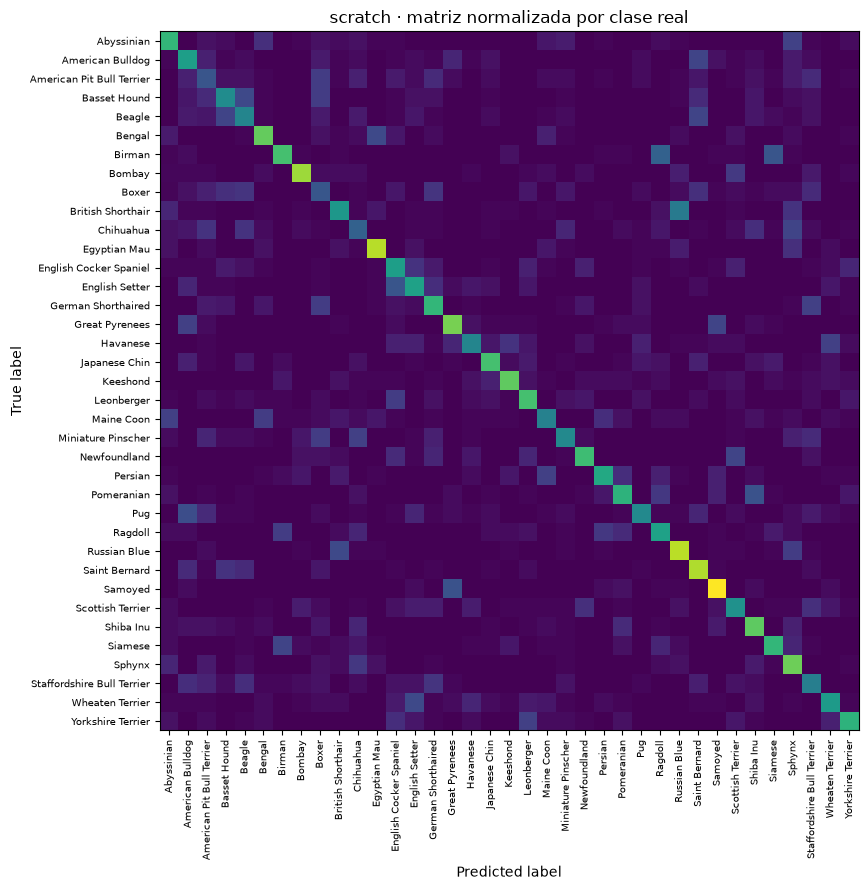

Errores,Clase real,Predicción
28,British Shorthair,Russian Blue
21,Birman,Ragdoll
18,English Setter,English Cocker Spaniel
18,Birman,Siamese
17,Samoyed,Great Pyrenees


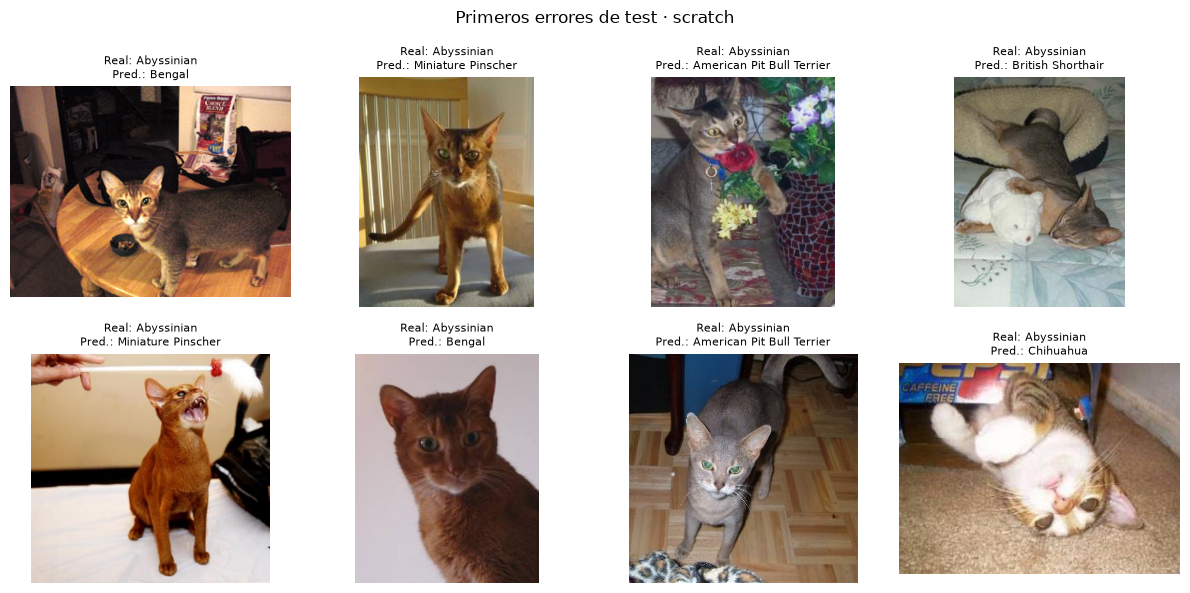

**scratch** acierta **1547 de 3669 imágenes** y comete **2122 errores**. La clase con menor F1 es **Boxer** (**0.168**). La matriz normalizada compara la proporción de aciertos de cada clase; los pares anteriores muestran el número absoluto de confusiones.

### Resultados por clase: mobilenet

,precision,recall,f1-score,support
Abyssinian,0.851,0.816,0.833,98.0
American Bulldog,0.718,0.840,0.774,100.0
American Pit Bull Terrier,0.769,0.500,0.606,100.0
Basset Hound,0.967,0.870,0.916,100.0
Beagle,0.873,0.890,0.881,100.0
Bengal,0.872,0.680,0.764,100.0
Birman,0.762,0.800,0.780,100.0
Bombay,0.927,0.864,0.894,88.0
Boxer,0.815,0.889,0.850,99.0
British Shorthair,0.780,0.780,0.780,100.0


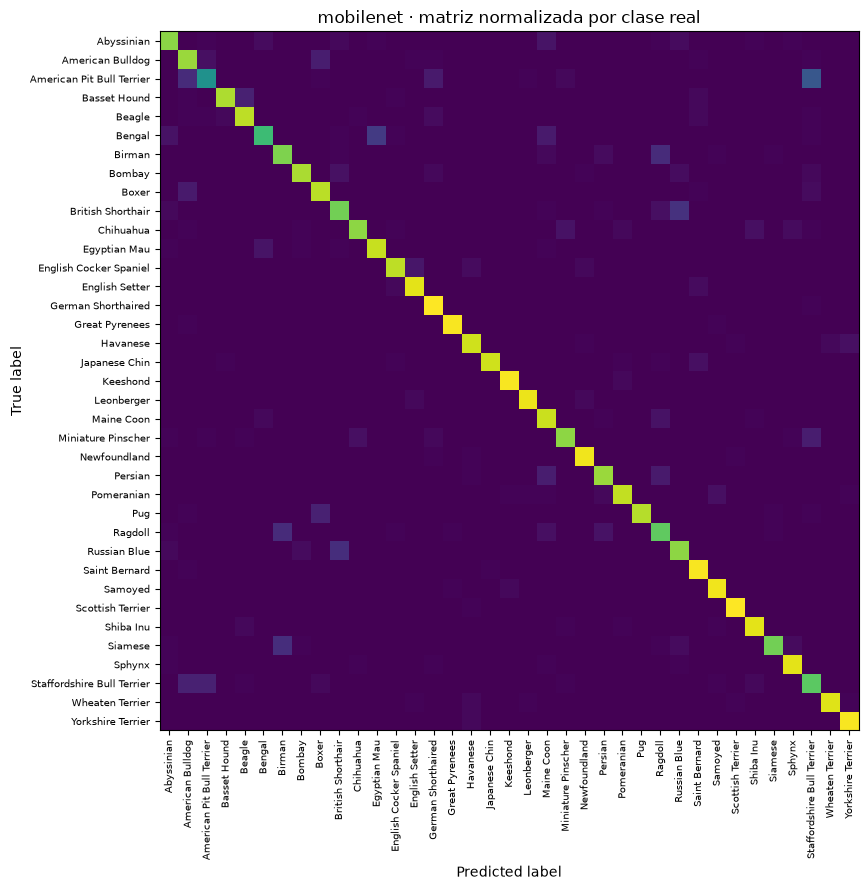

Errores,Clase real,Predicción
27,American Pit Bull Terrier,Staffordshire Bull Terrier
17,Bengal,Egyptian Mau
14,British Shorthair,Russian Blue
13,Siamese,Birman
13,Russian Blue,British Shorthair


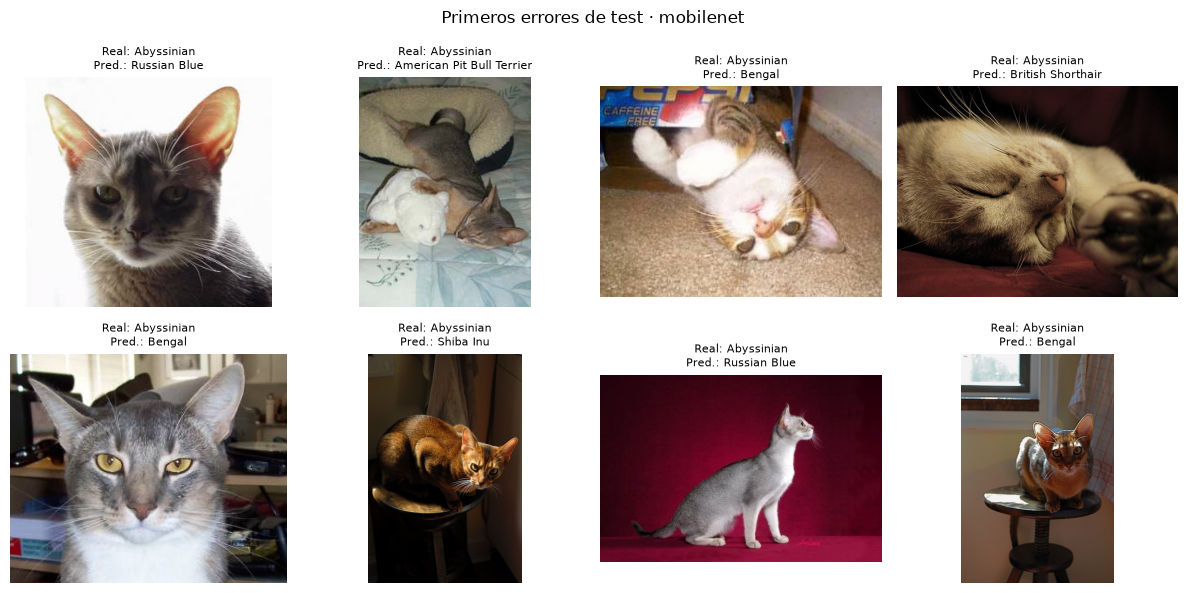

**mobilenet** acierta **3216 de 3669 imágenes** y comete **453 errores**. La clase con menor F1 es **American Pit Bull Terrier** (**0.606**). La matriz normalizada compara la proporción de aciertos de cada clase; los pares anteriores muestran el número absoluto de confusiones.

### Resultados por clase: efficientnet

,precision,recall,f1-score,support
Abyssinian,0.851,0.878,0.864,98.0
American Bulldog,0.769,0.800,0.784,100.0
American Pit Bull Terrier,0.701,0.680,0.690,100.0
Basset Hound,0.958,0.920,0.939,100.0
Beagle,0.885,0.920,0.902,100.0
Bengal,0.841,0.900,0.870,100.0
Birman,0.757,0.780,0.768,100.0
Bombay,0.945,0.977,0.961,88.0
Boxer,0.812,0.919,0.863,99.0
British Shorthair,0.889,0.720,0.796,100.0


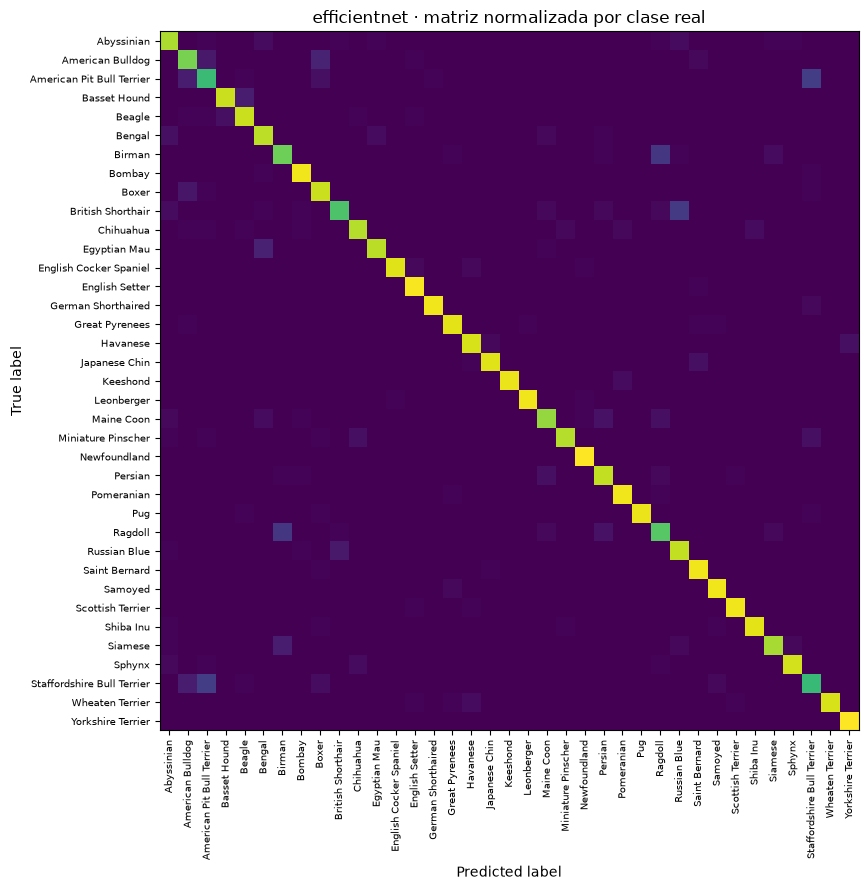

Errores,Clase real,Predicción
18,American Pit Bull Terrier,Staffordshire Bull Terrier
17,British Shorthair,Russian Blue
16,Staffordshire Bull Terrier,American Pit Bull Terrier
16,Ragdoll,Birman
16,Birman,Ragdoll


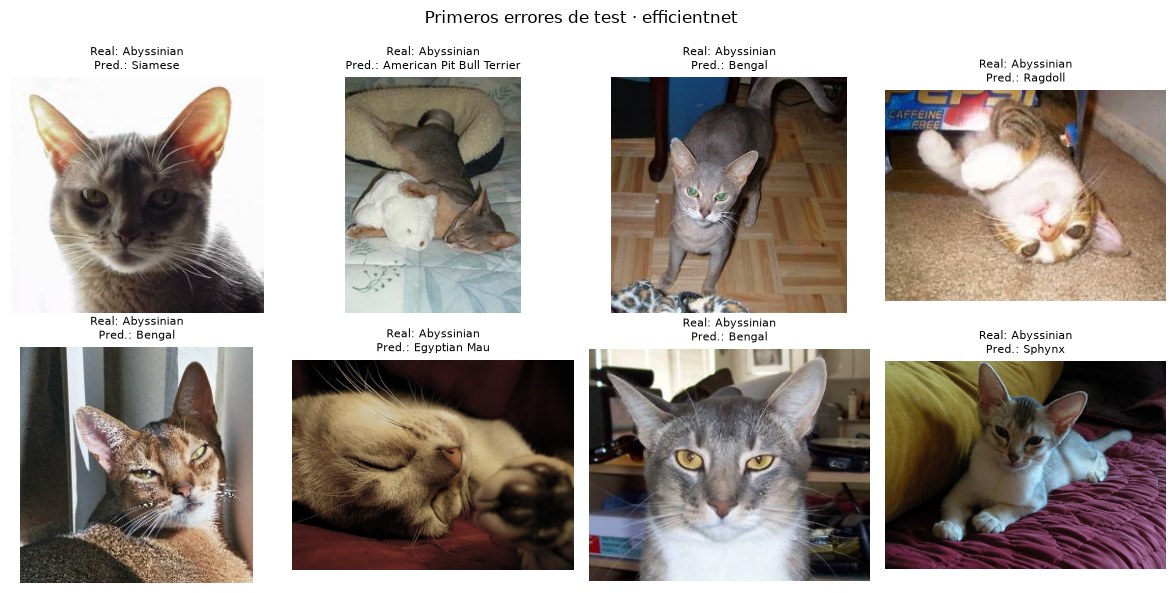

**efficientnet** acierta **3329 de 3669 imágenes** y comete **340 errores**. La clase con menor F1 es **Staffordshire Bull Terrier** (**0.682**). La matriz normalizada compara la proporción de aciertos de cada clase; los pares anteriores muestran el número absoluto de confusiones.

In [21]:
class_reports = {}
error_pairs = {}
y = test_df.label.to_numpy()
labels = np.arange(len(class_names))
for r in finalists:
    family = r['config']['family']
    pred = test_predictions[family].argmax(axis=1)
    report = pd.DataFrame(classification_report(y, pred, labels=labels,
        target_names=class_names, output_dict=True, zero_division=0)).T
    class_reports[family] = report
    display(Markdown('### Resultados por clase: ' + family))
    display(report.loc[class_names].round(3))
    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=labels, display_labels=class_names,
        normalize='true', include_values=False, xticks_rotation=90, ax=ax, colorbar=False)
    ax.set_title(family + ' · matriz normalizada por clase real')
    ax.tick_params(axis='both', labelsize=7)
    fig.tight_layout(); plt.show(); plt.close(fig)

    cm = confusion_matrix(y, pred, labels=labels)
    np.fill_diagonal(cm, 0)
    pairs = sorted([(int(cm[a, b]), class_names[a], class_names[b])
                    for a in labels for b in labels if cm[a, b]], reverse=True)[:5]
    error_pairs[family] = pairs
    show_table(pd.DataFrame(pairs, columns=['Errores', 'Clase real', 'Predicción']))
    mistakes = np.flatnonzero(pred != y)[:8]
    if len(mistakes):
        fig, axes = plt.subplots(2, 4, figsize=(12, 6))
        for ax in axes.flat: ax.axis('off')
        for ax, idx in zip(axes.flat, mistakes):
            with Image.open(test_df.iloc[idx].path) as img: ax.imshow(img.convert('RGB'))
            ax.set_title('Real: ' + class_names[y[idx]] + '\nPred.: ' + class_names[pred[idx]], fontsize=8)
        fig.suptitle('Primeros errores de test · ' + family)
        fig.tight_layout(); plt.show(); plt.close(fig)
    correct = int(np.sum(pred == y))
    worst = report.loc[class_names, 'f1-score'].idxmin()
    display(Markdown(
        f"**{family}** acierta **{correct} de {len(y)} imágenes** y comete **{len(y)-correct} errores**. "
        f"La clase con menor F1 es **{worst}** (**{report.loc[worst, 'f1-score']:.3f}**). "
        "La matriz normalizada compara la proporción de aciertos de cada clase; "
        "los pares anteriores muestran el número absoluto de confusiones."))


<a id="s12"></a>

## 12. Comparación final y conclusiones

Comparamos rendimiento, brechas de generalización, tamaño y tiempo de entrenamiento.
El tiempo de una solución preentrenada suma su cabeza y su ajuste fino, cuando lo hay;
no incluye el coste original de ImageNet. El tiempo total de la búsqueda incluye también
los ensayos que no terminaron siendo finalistas. Son costes distintos.

Las conclusiones numéricas siguientes se generan con esta ejecución. Las curvas y las
comparaciones intermedias permiten revisar qué decisiones condujeron a la selección final.


,Acc. train,Acc. valid.,Acc. test,F1 valid.,F1 test,Brecha train–valid.
Red,,,,,,
scratch,0.9660,0.4647,0.4216,0.4605,0.4235,0.5014
mobilenet,0.9898,0.8954,0.8765,0.8948,0.8755,0.0944
efficientnet,0.9820,0.9212,0.9073,0.9212,0.9068,0.0608


Red,Resolución,Parámetros,Entrenables en esta fase,Minutos de la solución
scratch,128,1212805,1210885,4.28
mobilenet,224,2305381,1558117,1.10
efficientnet,224,4096968,2556085,1.50


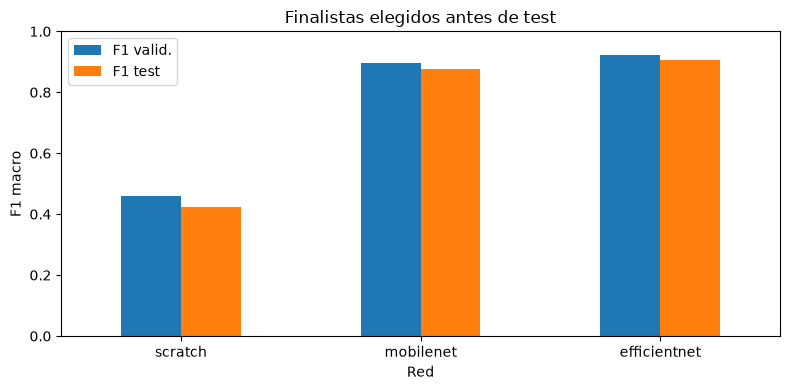

Elegimos **efficientnet** por validación. En test obtiene accuracy **90.73%** y F1 macro **0.9068**. La clasificación por F1 en test confirma esa elección.

La búsqueda scratch pasa de un F1 de validación **0.3080** en la base a **0.3602** en la primera ronda y **0.4605** en la selección final. La CNN elegida alcanza accuracy **96.60%** en entrenamiento sin aumentos y **46.47%** en validación, una brecha de **+50.14%**. Esa separación debe leerse junto a las curvas: mejorar el ajuste a entrenamiento no garantiza generalizar mejor.

La mejor red preentrenada difiere de la CNN propia en **+0.4833** de F1 de test. Las características aprendidas previamente resultan útiles con este conjunto pequeño. No podemos atribuir toda la diferencia al preentrenamiento, porque también cambian arquitectura y resolución.

La mayor variación entre semillas corresponde a **scratch**, con desviación **0.0299** del F1 de validación. Las repeticiones ayudan a interpretar la estabilidad de la comparación, pero no sustituyen más particiones. Las matrices y los ejemplos muestran además qué clases siguen siendo difíciles, algo que una sola accuracy oculta.

**Ejecución completada:** 54 entrenamientos distintos, 1144 épocas y tres evaluaciones de test. Tiempo transcurrido: **1:37:39**. Historiales, predicciones y métricas comprobados.

In [22]:
comparison = pd.DataFrame([{
    'Red': r['config']['family'], 'Acc. train': r['train_accuracy_clean'],
    'Acc. valid.': r['accuracy'], 'Acc. test': test_results[r['config']['family']]['accuracy'],
    'F1 valid.': r['f1_macro'], 'F1 test': test_results[r['config']['family']]['f1_macro'],
    'Brecha train–valid.': r['train_accuracy_clean'] - r['accuracy']
} for r in finalists]).set_index('Red')
display(comparison.round(4))
show_table(pd.DataFrame([{'Red': r['config']['family'], 'Resolución': r['config']['size'],
    'Parámetros': r['parameters'], 'Entrenables en esta fase': r['trainable_parameters'],
    'Minutos de la solución': r['cumulative_seconds'] / 60} for r in finalists]).round(2))
fig, ax = plt.subplots(figsize=(8, 4))
comparison[['F1 valid.', 'F1 test']].plot.bar(ax=ax, rot=0, ylim=(0, 1))
ax.set(ylabel='F1 macro', title='Finalistas elegidos antes de test')
fig.tight_layout(); plt.show(); plt.close(fig)

preferred_family = preferred['config']['family']
best_test_family = max(test_results, key=lambda f: test_results[f]['f1_macro'])
winner = test_results[preferred_family]
test_agreement = ('La clasificación por F1 en test confirma esa elección.'
    if preferred_family == best_test_family else
    f'El mayor F1 en test lo obtiene {best_test_family}; lo registramos sin cambiar retrospectivamente la selección.')
display(Markdown(
    f"Elegimos **{preferred_family}** por validación. En test obtiene accuracy "
    f"**{winner['accuracy']:.2%}** y F1 macro **{winner['f1_macro']:.4f}**. {test_agreement}"))

scratch_gap = selected_scratch['train_accuracy_clean'] - selected_scratch['accuracy']
display(Markdown(
    f"La búsqueda scratch pasa de un F1 de validación **{base_trial['f1_macro']:.4f}** "
    f"en la base a **{first_scratch['f1_macro']:.4f}** en la primera ronda y "
    f"**{selected_scratch['f1_macro']:.4f}** en la selección final. "
    f"La CNN elegida alcanza accuracy **{selected_scratch['train_accuracy_clean']:.2%}** "
    f"en entrenamiento sin aumentos y **{selected_scratch['accuracy']:.2%}** en validación, "
    f"una brecha de **{scratch_gap:+.2%}**. "
    "Esa separación debe leerse junto a las curvas: mejorar el ajuste a entrenamiento no garantiza generalizar mejor."))

transfer_delta = max(test_results[f]['f1_macro'] for f in ['mobilenet', 'efficientnet']) - test_results['scratch']['f1_macro']
if transfer_delta > 0:
    interpretation = ('Las características aprendidas previamente resultan útiles con este conjunto pequeño. '
        'No podemos atribuir toda la diferencia al preentrenamiento, porque también cambian arquitectura y resolución.')
else:
    interpretation = ('En esta ejecución, partir de ImageNet no supera el F1 de la CNN propia. '
        'Este resultado corresponde a las arquitecturas, resoluciones y presupuestos concretos ensayados.')
display(Markdown(
    f"La mejor red preentrenada difiere de la CNN propia en **{transfer_delta:+.4f}** de F1 de test. "
    + interpretation))

most_variable = final_seed_stats['std'].idxmax()
display(Markdown(
    f"La mayor variación entre semillas corresponde a **{most_variable}**, con desviación "
    f"**{final_seed_stats.loc[most_variable, 'std']:.4f}** del F1 de validación. "
    "Las repeticiones ayudan a interpretar la estabilidad de la comparación, pero no sustituyen más particiones. "
    "Las matrices y los ejemplos muestran además qué clases siguen siendo difíciles, algo que una sola accuracy oculta."))

# Comprobación final de coherencia: no depende de ningún archivo de resultados externo.
assert set(test_results) == {'scratch', 'mobilenet', 'efficientnet'}
assert all(len(r['history']['loss']) == r['epochs_run'] for r in TRIALS.values())
for r in finalists:
    family = r['config']['family']
    recalculated = metrics_from_probabilities(y, test_predictions[family])
    for key in ['accuracy', 'f1_macro', 'cross_entropy', 'top3_accuracy']:
        assert np.isclose(recalculated[key], test_results[family][key])
    assert checkpoint_digest(r['checkpoint']) == selection_fingerprints[r['trial_id']]
display(Markdown(
    f"**Ejecución completada:** {len(TRIALS)} entrenamientos distintos, "
    f"{sum(r['epochs_run'] for r in TRIALS.values())} épocas y tres evaluaciones de test. "
    f"Tiempo transcurrido: **{duration_text(time.perf_counter()-execution_start)}**. "
    "Historiales, predicciones y métricas comprobados."))


<a id="limites"></a>

### Limitaciones

Todas las decisiones utilizan una única partición de validación. Consultarla en muchas
pruebas puede adaptar las elecciones a ella. Las tres semillas miden variación del
entrenamiento, no incertidumbre debida a otras particiones. Las primeras ablaciones
usan una semilla y presupuestos limitados: sus resultados no permiten afirmar que una
técnica sea buena o mala en general.

La CNN trabaja a 128×128 y las preentrenadas a 224×224. Comparamos soluciones completas,
sin aislar el efecto de resolución, arquitectura y datos de preentrenamiento. El cribado
corto favorece a modelos que aprenden pronto; recuperar un candidato no elimina ese sesgo.
Tampoco medimos latencia de inferencia ni consumo energético.

El test ya se había consultado en versiones anteriores. Aunque esta ejecución fija la
selección antes de evaluarlo, eso no convierte el estudio completo en una prueba ciega.
Comprobamos identificadores disjuntos, pero no hacemos una auditoría de duplicados
visuales ni del posible solapamiento con los datos usados para preentrenar.

Para continuar tendría sentido igualar resoluciones y repetir con otras particiones
u otros recortes e intensidades de aumento. Sería un estudio nuevo, con un protocolo
y una evaluación independiente. El trabajo realizado nos ha servido para relacionar
arquitectura, entrenamiento y generalización, y para justificar una elección con evidencia,
incluso cuando no coincide con la estrategia que más nos interesaba explorar.

[Volver al índice](#indice)


<a id="referencias"></a>

## Referencias

1. Enunciado de 07MIAR: *Deep Vision in classification tasks*. Requisitos de experimentación y entrega.
2. Parkhi, O. M. et al. (2012). *Cats and Dogs*. CVPR. [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/).
3. Keras. [Transfer learning y fine-tuning](https://keras.io/guides/transfer_learning/).
4. Keras. [MobileNetV2](https://keras.io/api/applications/mobilenet/) y [EfficientNet](https://keras.io/api/applications/efficientnet/).
5. Keras. [ModelCheckpoint](https://keras.io/api/callbacks/model_checkpoint/),
   [EarlyStopping](https://keras.io/api/callbacks/early_stopping/) y
   [ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).
6. Keras. [Callbacks personalizados](https://keras.io/guides/writing_your_own_callbacks/).
   IPython. [Salidas actualizables](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html).

[Volver al índice](#indice)
